# Predicting At-Risk Students in Online Learning
### Traditional Machine Learning vs Deep Learning on the Open University Learning Analytics Dataset (OULAD)

**Author:** Aderline Gashugi, African Leadership University

**Module:** Machine Learning, Summative Project

## What this notebook does

Many students who start an online course never finish it. My goal is to find those students **early**, using only what a university already knows by the end of the fourth week of a course, so that a tutor still has time to reach out.

The task is a binary classification problem:

* **1 = at risk**: the student ends the course with `Fail` or `Withdrawn`
* **0 = not at risk**: the student ends with `Pass` or `Distinction`

I compare two families of models on the same data and the same splits:

1. **Traditional machine learning** with scikit-learn (Logistic Regression, Random Forest, Gradient Boosting, SVM)
2. **Deep learning** with TensorFlow/Keras (a Sequential MLP and a two-input Functional model), fed through `tf.data` pipelines

## Notebook map

| Section | Content |
|---|---|
| 1 | Setup, seeds and configuration |
| 2 | Data loading |
| 3 | Building the cohort and the target |
| 4 | Feature engineering |
| 5 | Exploratory data analysis |
| 6 | Train / validation / test split |
| 7 | Preprocessing pipeline |
| 8 | Experiment helpers |
| 9 | Traditional ML experiments (ML-01 to ML-10) |
| 10 | Deep learning experiments (DL-01 to DL-09) |
| 11 | Results table |
| 12 | Evaluation: learning curves, ROC, confusion matrices |
| 13 | Error analysis |
| 14 | Saving the best models |
| 15 | Conclusions |

Every experiment has an ID (for example `ML-04` or `DL-07`). The same IDs are used in the TensorBoard logs, in `results/experiments.csv` and in the experiment table of my report, so each number in the report can be traced back to a run here.

## 1. Setup, seeds and configuration

All the libraries below are already installed on Google Colab. If you run the notebook somewhere else, uncomment the `pip` line. The exact versions I used are in `requirements.txt`.

In [1]:
# !pip install -q -r requirements.txt

In [2]:
import os
import json
import time
import zipfile
import warnings
import urllib.request
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["PYTHONWARNINGS"] = "ignore"  # also silences the parallel worker processes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, RandomizedSearchCV,
                                     StratifiedGroupKFold, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorboard.plugins.hparams import api as hp

warnings.filterwarnings("ignore")
print("TensorFlow", tf.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

TensorFlow 2.20.0 | scikit-learn 1.6.1 | pandas 2.3.3


### Reproducibility

I fix one seed for Python, NumPy and TensorFlow, and I reset it before each Keras model is built so that the result of an experiment does not depend on which experiments ran before it.

In [3]:
SEED = 42


def set_seed(seed=SEED):
    """Seed Python, NumPy and TensorFlow in one call."""
    keras.utils.set_random_seed(seed)


set_seed()
tf.config.experimental.enable_op_determinism()

### Configuration

All the choices that shape the problem are in one place. The most important one is `CUTOFF_DAY`. A value of 28 means the models only see what happened **before day 28** of the course (the first four weeks). Anything that happens later is hidden from them, because in real use it would not exist yet.

In [4]:
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
RESULT_DIR = Path("results")
for d in (DATA_DIR, LOG_DIR, MODEL_DIR, FIG_DIR, RESULT_DIR):
    d.mkdir(exist_ok=True)

DATA_URL = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"

CUTOFF_DAY = 28          # models only see days before this one
SEQ_START = -14          # the daily click sequence starts two weeks before the course opens
SEQ_LEN = CUTOFF_DAY - SEQ_START
KEYS = ["code_module", "code_presentation", "id_student"]

# Colours used in every figure
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"
GREY, GRID = "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 10, "font.size": 10, "legend.frameon": False,
})


def save_fig(name):
    """Save the current figure into figures/ so the report can use it."""
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 2. Data loading

The Open University Learning Analytics Dataset (OULAD) is published on the UCI Machine Learning Repository under a CC BY 4.0 licence. It has seven linked CSV files. The raw files are **not** stored in the GitHub repository. The cell below downloads the zip from UCI the first time it runs and reuses the local copy afterwards.

In [5]:
def find_csv_dir(root):
    """Return the folder that holds studentInfo.csv, or None."""
    hits = list(Path(root).rglob("studentInfo.csv"))
    return hits[0].parent if hits else None


def fetch_data(data_dir=DATA_DIR, url=DATA_URL):
    """Download and unzip OULAD if it is not already in data_dir."""
    csv_dir = find_csv_dir(data_dir)
    if csv_dir is None:
        zip_path = Path(data_dir) / "oulad.zip"
        if not zip_path.exists():
            print("Downloading OULAD from UCI ...")
            urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(data_dir)
        # some copies of the archive contain a second zip inside
        for inner in Path(data_dir).rglob("*.zip"):
            if inner != zip_path:
                with zipfile.ZipFile(inner) as z:
                    z.extractall(data_dir)
        csv_dir = find_csv_dir(data_dir)
    return csv_dir


def load_tables(csv_dir):
    """Read the seven OULAD tables. Missing values appear as '?' or as empty cells."""
    na = ["?", ""]
    tables = {name: pd.read_csv(csv_dir / f"{name}.csv", na_values=na)
              for name in ["studentInfo", "studentRegistration", "courses",
                           "assessments", "studentAssessment", "vle"]}
    tables["studentVle"] = pd.read_csv(
        csv_dir / "studentVle.csv",
        dtype={"code_module": "category", "code_presentation": "category",
               "id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"})
    return tables


CSV_DIR = fetch_data()
T = load_tables(CSV_DIR)
pd.DataFrame({"rows": {k: len(v) for k, v in T.items()},
              "columns": {k: v.shape[1] for k, v in T.items()}})

,rows,columns
studentInfo,32593,12
studentRegistration,32593,5
courses,22,3
assessments,206,6
studentAssessment,173912,5
vle,6364,6
studentVle,10655280,6


**What I see:** all seven tables loaded. `studentInfo` has **32,593 rows**, which is well above the 20,000-row minimum for this project, and the click log (`studentVle`) has **10,655,280 rows**. These counts match the numbers published with the dataset by Kuzilek et al. (2017), so the copy I am using is complete.

In [6]:
T["studentInfo"].head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


### Quick quality checks on the raw tables

Before building anything I check for duplicates, impossible values and missing values.

In [7]:
info = T["studentInfo"]
print("Rows in studentInfo:", len(info))
print("Duplicate student-course rows:", info.duplicated(KEYS).sum())
print("Unique students:", info["id_student"].nunique(),
      "| students who appear in more than one course:", (info["id_student"].value_counts() > 1).sum())
print("Negative click counts:", (T["studentVle"]["sum_click"] < 0).sum())
print("Scores outside 0-100:", (~T["studentAssessment"]["score"].dropna().between(0, 100)).sum())

missing = pd.concat({name: df.isna().sum() for name, df in T.items() if name != "studentVle"})
missing = missing[missing > 0].rename("missing values").to_frame()
missing["% of table"] = [round(100 * v / len(T[t]), 2) for (t, _), v in zip(missing.index, missing["missing values"])]
missing

Rows in studentInfo: 32593
Duplicate student-course rows: 0
Unique students: 28785 | students who appear in more than one course: 3538
Negative click counts: 0
Scores outside 0-100: 0


missing values  % of table
studentInfo         imd_band                       1111        3.41
studentRegistration date_registration                45        0.14
                    date_unregistration           22521       69.10
assessments         date                             11        5.34
studentAssessment   score                           173        0.10
vle                 week_from                      5243       82.39
                    week_to                        5243       82.39

**What I see:**

* There are no duplicate student-course rows, no negative click counts and no scores outside 0 to 100, so I do not need to remove any impossible values.
* 3,538 students appear in more than one course. This is the reason the split in section 6 is done by student.
* `imd_band` (the deprivation band of the student's area) is missing for 1,111 students (3.4%). I keep these students and give them an `"Unknown"` category instead of dropping them.
* `date_unregistration` is missing for 69% of rows. That is not an error, because it is only filled in for students who withdrew. I use it to build the cohort and **never** as a feature, because it is the answer to the question.
* `week_from` / `week_to` in `vle` are 82% missing, so I do not use them.

## 3. Building the cohort and the target

One row in `studentInfo` is one student taking one course presentation. That is the unit I classify.

Two groups of rows are removed, and both removals are about honesty rather than convenience:

* **Students who had already withdrawn before the cutoff day.** Their outcome is already known on day 28, so "predicting" it would be cheating and would make every model look better than it is.
* **Students who registered on or after the cutoff day.** They have no four-week history to learn from.

In [8]:
def build_cohort(tables, cutoff=CUTOFF_DAY):
    """Join student info with registration dates, filter the cohort and create the target."""
    df = tables["studentInfo"].merge(tables["studentRegistration"], on=KEYS, how="left")
    df = df.merge(tables["courses"], on=["code_module", "code_presentation"], how="left")

    left_early = df["date_unregistration"].notna() & (df["date_unregistration"] < cutoff)
    came_late = df["date_registration"].notna() & (df["date_registration"] >= cutoff)
    steps = {"raw rows": len(df),
             "withdrew before cutoff (removed)": int(left_early.sum()),
             "registered on/after cutoff (removed)": int((came_late & ~left_early).sum())}
    df = df[~left_early & ~came_late].reset_index(drop=True)
    steps["rows kept"] = len(df)

    df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
    df["start_month"] = df["code_presentation"].str[-1].map({"B": "February", "J": "October"})
    return df, steps


cohort, cohort_steps = build_cohort(T)
print(pd.Series(cohort_steps).to_string())
print("\nFinal result in the kept cohort:")
print(cohort["final_result"].value_counts().to_string())
print(f"\nAt-risk rate: {cohort['at_risk'].mean():.1%}")

raw rows                                32593
withdrew before cutoff (removed)         5040
registered on/after cutoff (removed)       18
rows kept                               27535

Final result in the kept cohort:
final_result
Pass           12356
Fail            7037
Withdrawn       5119
Distinction     3023

At-risk rate: 44.1%


**What I see:** 5,040 students had already withdrawn before day 28 and 18 registered too late, so **27,535 rows** remain. That is still more than 20,000.

**44.1%** of the remaining students are at risk. Removing the early leavers made the task harder on purpose. These are the easiest cases to "predict", and keeping them would have made every model look better than it would be in real use.

## 4. Feature engineering

The raw tables cannot be fed to a model directly. The click log alone has more than ten million rows, with many rows per student. I turn them into one row per student with three groups of features:

| Group | What it describes | Examples |
|---|---|---|
| **Registration** | What is known on the day a student signs up | course, region, previous education, deprivation band, age band, credits, how early they registered |
| **VLE activity** | How the student used the online learning environment before day 28 | total clicks, active days, clicks per week, clicks per type of material, day of last activity, trend from week 1 to week 4 |
| **Assessment** | Early coursework due before day 28 | number submitted, share submitted, mean score, late submissions |

I also keep the **daily click sequence** (42 values, from day -14 to day 27) for the deep learning models that can read a sequence directly.

Every feature only uses records dated before the cutoff day. This rule is enforced inside the functions.

In [9]:
ACTIVITY_TYPES = ["homepage", "oucontent", "forumng", "subpage", "resource",
                  "quiz", "url", "ouwiki", "oucollaborate", "externalquiz"]


def vle_features(tables, cohort, cutoff=CUTOFF_DAY, seq_start=SEQ_START):
    """Aggregate the click log before the cutoff into per-student features and a daily sequence."""
    log = tables["studentVle"]
    log = log[log["date"] < cutoff].copy()
    site_type = tables["vle"].set_index("id_site")["activity_type"]
    kind = log["id_site"].map(site_type)
    log["kind"] = np.where(kind.isin(ACTIVITY_TYPES), kind, "other")

    index = pd.MultiIndex.from_frame(cohort[KEYS])
    grouped = log.groupby(KEYS, observed=True)
    feats = grouped.agg(total_clicks=("sum_click", "sum"),
                        active_days=("date", "nunique"),
                        n_sites=("id_site", "nunique"),
                        first_active_day=("date", "min"),
                        last_active_day=("date", "max"))
    before = log[log["date"] < 0].groupby(KEYS, observed=True).agg(
        clicks_before_start=("sum_click", "sum"),
        active_days_before_start=("date", "nunique"))
    by_kind = log.groupby(KEYS + ["kind"], observed=True)["sum_click"].sum().unstack(fill_value=0)
    by_kind = by_kind.reindex(columns=ACTIVITY_TYPES + ["other"], fill_value=0).add_prefix("clicks_")

    feats = feats.join(before).join(by_kind)
    feats.index = pd.MultiIndex.from_arrays(
        [feats.index.get_level_values(k).astype(t) for k, t in zip(KEYS, [str, str, int])], names=KEYS)
    feats = feats.reindex(index)

    daily = (log[log["date"] >= seq_start]
             .groupby(KEYS + ["date"], observed=True)["sum_click"].sum().unstack(fill_value=0))
    daily.index = pd.MultiIndex.from_arrays(
        [daily.index.get_level_values(k).astype(t) for k, t in zip(KEYS, [str, str, int])], names=KEYS)
    daily = daily.reindex(index=index, columns=range(seq_start, cutoff), fill_value=0).fillna(0)

    # students with no clicks at all: counts are 0, first/last active day stay missing
    count_cols = [c for c in feats.columns if c not in ("first_active_day", "last_active_day")]
    feats[count_cols] = feats[count_cols].fillna(0)

    weeks = {f"clicks_week{w + 1}": daily.loc[:, 7 * w: 7 * w + 6].sum(axis=1) for w in range(cutoff // 7)}
    feats = feats.assign(**weeks)
    feats["clicks_per_active_day"] = feats["total_clicks"] / feats["active_days"].clip(lower=1)
    feats["active_weeks"] = sum((feats[c] > 0).astype(int) for c in weeks)
    last_week = f"clicks_week{cutoff // 7}"
    feats["click_trend"] = np.log1p(feats[last_week]) - np.log1p(feats["clicks_week1"])
    return feats.reset_index(drop=True), daily.to_numpy(dtype="float32")


def assessment_features(tables, cohort, cutoff=CUTOFF_DAY):
    """Features from assessments that were due, and submitted, before the cutoff."""
    due = tables["assessments"]
    due = due[due["date"].notna() & (due["date"] < cutoff)]
    n_due = due.groupby(["code_module", "code_presentation"]).size().rename("n_assess_due")

    sub = tables["studentAssessment"].merge(
        due[["id_assessment", "code_module", "code_presentation", "date"]], on="id_assessment")
    sub = sub[sub["date_submitted"] < cutoff]
    sub["late"] = (sub["date_submitted"] > sub["date"]).astype(int)
    sub["days_early"] = sub["date"] - sub["date_submitted"]
    per_student = sub.groupby(KEYS).agg(n_submitted=("id_assessment", "nunique"),
                                        mean_score=("score", "mean"),
                                        n_late=("late", "sum"),
                                        mean_days_early=("days_early", "mean"))

    out = cohort[KEYS].merge(n_due, left_on=["code_module", "code_presentation"], right_index=True, how="left")
    out = out.merge(per_student, left_on=KEYS, right_index=True, how="left")
    out[["n_assess_due", "n_submitted", "n_late"]] = out[["n_assess_due", "n_submitted", "n_late"]].fillna(0)
    out["submit_rate"] = out["n_submitted"] / out["n_assess_due"].clip(lower=1)
    return out.drop(columns=KEYS).reset_index(drop=True)


vle_feats, X_seq_raw = vle_features(T, cohort)
assess_feats = assessment_features(T, cohort)
data = pd.concat([cohort, vle_feats, assess_feats], axis=1)
print("Feature table:", data.shape, "| daily sequence array:", X_seq_raw.shape)
data[["total_clicks", "active_days", "last_active_day", "click_trend", "n_assess_due", "n_submitted", "mean_score"]].describe().round(2)

Feature table: (27535, 48) | daily sequence array: (27535, 42)


,total_clicks,active_days,last_active_day,click_trend,n_assess_due,n_submitted,mean_score
count,27535.00,27535.00,26613.00,27535.00,27535.00,27535.00,20007.00
mean,351.01,14.37,23.29,-0.24,0.86,0.76,72.72
std,423.72,10.14,5.93,1.84,0.45,0.50,21.67
min,0.00,0.00,-24.00,-6.53,0.00,0.00,0.00
25%,88.00,6.00,23.00,-1.22,1.00,0.00,65.00
50%,221.00,12.00,25.00,-0.07,1.00,1.00,77.00
75%,462.00,21.00,27.00,0.66,1.00,1.00,87.00
max,7570.00,53.00,27.00,6.45,2.00,2.00,100.00


### Feature groups

I name the feature groups so that later experiments can switch them on one at a time. This lets me measure how much each group of engineered features actually adds.

Columns are also sorted by how they need to be treated:

* `*_CAT`: categories, one-hot encoded
* `*_LOG`: counts that are zero or positive and heavily right-skewed, so they get a `log1p` transform before scaling
* `*_NUM`: other numbers, which are only imputed and standardised

In [10]:
REG_CAT = ["code_module", "start_month", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
REG_LOG = ["num_of_prev_attempts", "studied_credits"]
REG_NUM = ["date_registration", "module_presentation_length"]

VLE_LOG = (["total_clicks", "active_days", "n_sites", "clicks_before_start", "active_days_before_start",
            "clicks_per_active_day"]
           + [f"clicks_week{w}" for w in range(1, CUTOFF_DAY // 7 + 1)]
           + [f"clicks_{k}" for k in ACTIVITY_TYPES + ["other"]])
VLE_NUM = ["first_active_day", "last_active_day", "active_weeks", "click_trend"]

ASSESS_LOG = ["n_assess_due", "n_submitted", "n_late"]
ASSESS_NUM = ["submit_rate", "mean_score", "mean_days_early"]

CAT_COLS = REG_CAT
LOG_COLS = REG_LOG + VLE_LOG + ASSESS_LOG
NUM_COLS = REG_NUM + VLE_NUM + ASSESS_NUM

FEATURE_SETS = {
    "registration": REG_CAT + REG_LOG + REG_NUM,
    "registration+vle": REG_CAT + REG_LOG + REG_NUM + VLE_LOG + VLE_NUM,
    "all": REG_CAT + REG_LOG + REG_NUM + VLE_LOG + VLE_NUM + ASSESS_LOG + ASSESS_NUM,
}
{k: len(v) for k, v in FEATURE_SETS.items()}

{'registration': 12, 'registration+vle': 37, 'all': 43}

## 5. Exploratory data analysis

### 5.1 Class balance

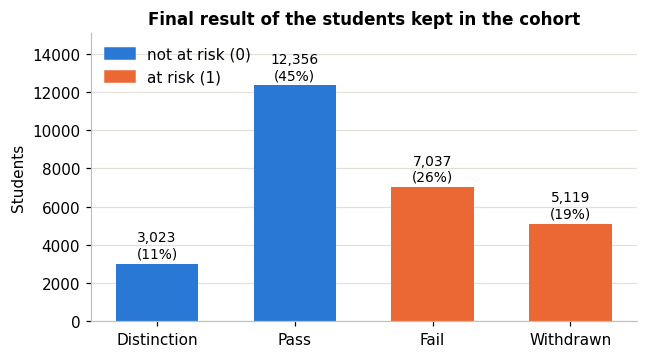

In [11]:
order = ["Distinction", "Pass", "Fail", "Withdrawn"]
counts = cohort["final_result"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.bar(order, counts.values, color=[BLUE, BLUE, ORANGE, ORANGE], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}\n({v / counts.sum():.0%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.22)
ax.set_ylabel("Students")
ax.set_title("Final result of the students kept in the cohort")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["not at risk (0)", "at risk (1)"], loc="upper left")
ax.grid(axis="x", visible=False)
save_fig("fig01_class_balance")

**What I see:** Pass is the largest group (12,356, 45%), followed by Fail (7,037, 26%), Withdrawn (5,119, 19%) and Distinction (3,023, 11%). After merging, the two classes are 56% not at risk and 44% at risk.

That is only a mild imbalance, so I do not resample the data. I still report precision, recall, F1 and the precision-recall curve as well as accuracy, because a model that always says "not at risk" would already be 56% accurate.

### 5.2 Missing values in the feature table

In [12]:
feat_missing = data[FEATURE_SETS["all"]].isna().mean().mul(100).round(2)
feat_missing[feat_missing > 0].sort_values(ascending=False).rename("% missing").to_frame()

,% missing
mean_score,27.34
mean_days_early,27.32
imd_band,3.73
first_active_day,3.35
last_active_day,3.35
date_registration,0.03


**What I see:** after feature engineering only six columns have missing values, and each has a reason:

* `mean_score` and `mean_days_early` (27%) are missing when a student had nothing marked before day 28. For 4,990 rows the course had no assessment due before day 28 at all. Missing is also more common among at-risk students (33.7%) than others (22.3%), so the fact that it is missing is useful. The `add_indicator` option in the pipeline keeps this as its own 0/1 column.
* `first_active_day` / `last_active_day` (3.35%) are missing for the 922 students who never clicked anything before day 28.
* `imd_band` (3.7%) becomes the `"Unknown"` category.
* `date_registration` is missing for only 7 students and is filled with the training median.

### 5.3 Skew and outliers in the click features

Click counts have a long right tail: most students click a few hundred times and a small number click thousands of times. The table counts how many values the usual 1.5 x IQR rule would call outliers, before and after a `log1p` transform.

In [13]:
def outlier_share(s):
    """Share of values outside 1.5 x IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100


check_cols = ["total_clicks", "clicks_week1", "clicks_oucontent", "clicks_forumng", "studied_credits"]
skew_table = pd.DataFrame({
    "max": data[check_cols].max(),
    "median": data[check_cols].median(),
    "skew (raw)": data[check_cols].skew(),
    "skew (log1p)": np.log1p(data[check_cols]).skew(),
    "% outliers (raw)": data[check_cols].apply(outlier_share),
    "% outliers (log1p)": np.log1p(data[check_cols]).apply(outlier_share),
}).round(2)
skew_table

,max,median,skew (raw),skew (log1p),% outliers (raw),% outliers (log1p)
total_clicks,7570.0,221.0,3.48,-1.37,6.11,5.51
clicks_week1,4385.0,34.0,5.96,-0.46,6.98,0.00
clicks_oucontent,1936.0,28.0,3.55,-0.29,8.12,0.00
clicks_forumng,4099.0,35.0,6.38,-0.36,8.12,0.00
studied_credits,630.0,60.0,1.75,0.15,5.45,16.21


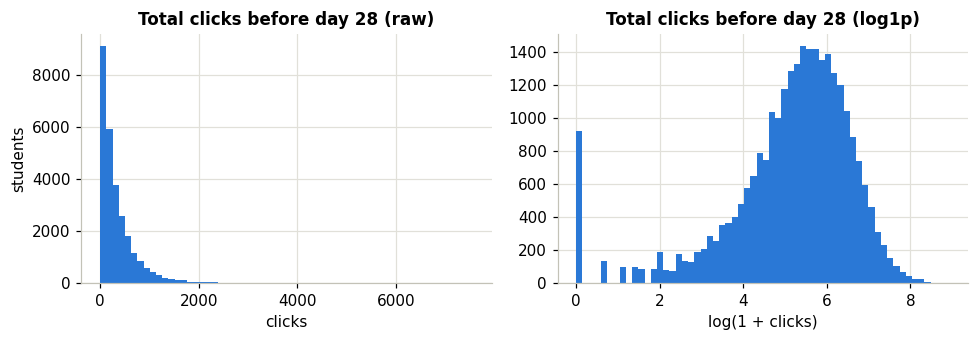

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(data["total_clicks"], bins=60, color=BLUE)
axes[0].set_title("Total clicks before day 28 (raw)")
axes[0].set_xlabel("clicks")
axes[0].set_ylabel("students")
axes[1].hist(np.log1p(data["total_clicks"]), bins=60, color=BLUE)
axes[1].set_title("Total clicks before day 28 (log1p)")
axes[1].set_xlabel("log(1 + clicks)")
plt.tight_layout()
save_fig("fig02_click_skew")

**What I see:** the click counts are very right-skewed. `total_clicks` has a median of 221 but a maximum of 7,570 (skew 3.48). After `log1p` the skew drops to -1.37 and the histogram looks much more like a bell shape, apart from a spike at zero for students who never logged in.

I do **not** delete the extreme values. A student with 7,000 clicks is unusual, but real, and they are exactly the kind of engaged student the model should learn about. The log transform shrinks their influence instead.

One honest note: for `studied_credits` the share of "outliers" goes **up** after the transform (5.45% to 16.21%). Most students take exactly 60 credits, so the IQR is very narrow and almost any other value counts as an outlier. This shows the IQR rule does not suit a column that is mostly one value. I still log-transform it because it is a count.

### 5.4 Does early behaviour separate the two classes?

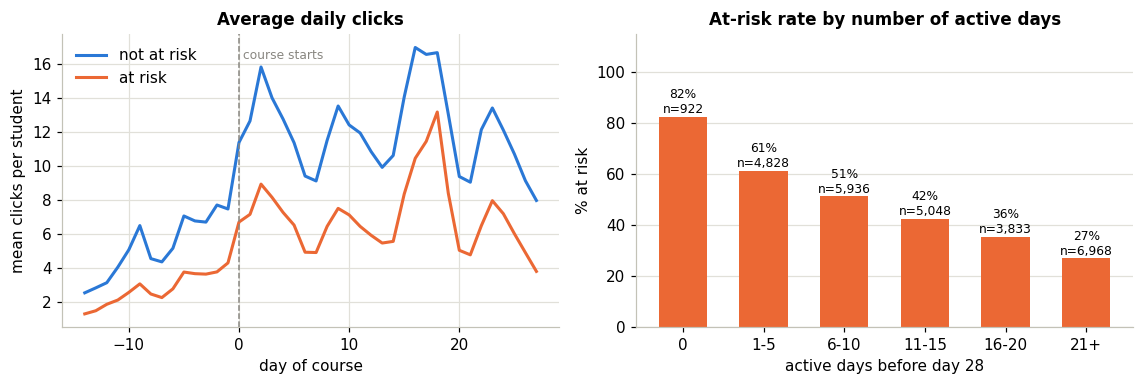

In [15]:
days = np.arange(SEQ_START, CUTOFF_DAY)
y_all = data["at_risk"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].plot(days, X_seq_raw[y_all == 0].mean(axis=0), color=BLUE, lw=2, label="not at risk")
axes[0].plot(days, X_seq_raw[y_all == 1].mean(axis=0), color=ORANGE, lw=2, label="at risk")
axes[0].axvline(0, color=GREY, lw=1, ls="--")
axes[0].text(0.4, axes[0].get_ylim()[1] * 0.95, "course starts", color=GREY, fontsize=8, va="top")
axes[0].set_xlabel("day of course")
axes[0].set_ylabel("mean clicks per student")
axes[0].set_title("Average daily clicks")
axes[0].legend()

bins = pd.cut(data["active_days"], [-1, 0, 5, 10, 15, 20, 60], labels=["0", "1-5", "6-10", "11-15", "16-20", "21+"])
rate = data.groupby(bins, observed=True)["at_risk"].agg(["mean", "size"])
b = axes[1].bar(rate.index.astype(str), rate["mean"] * 100, color=ORANGE, width=0.6)
for rect, (m, n) in zip(b, rate.values):
    axes[1].text(rect.get_x() + rect.get_width() / 2, m * 100 + 1.5, f"{m:.0%}\nn={int(n):,}", ha="center", fontsize=8)
axes[1].set_ylim(0, 115)
axes[1].set_xlabel("active days before day 28")
axes[1].set_ylabel("% at risk")
axes[1].set_title("At-risk rate by number of active days")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
save_fig("fig03_early_behaviour")

**What I see:**

* **Left:** both groups follow the same weekly rhythm, with peaks around day 2, day 9 and days 16 to 18 (probably when new material or the first assignment opens). But the at-risk line sits **below** the other one every single day, and it already does before the course starts. On average at-risk students click about half as much (median total 150 vs 293 clicks).
* **Right:** the at-risk rate falls steadily with the number of active days, from **82%** for students with no activity to **27%** for students active on 21 or more days.

This is the strongest early signal in the EDA and the main reason I engineered so many VLE features. It also shows the limits: even among students who were active on 21+ days, more than a quarter still end up at risk, so activity alone cannot explain everything.

### 5.5 At-risk rate across courses and deprivation bands

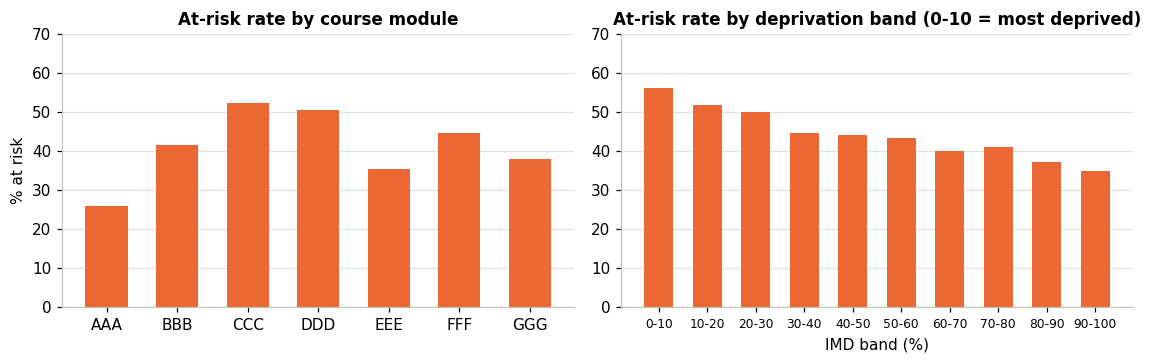

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
by_module = data.groupby("code_module")["at_risk"].mean().mul(100)
axes[0].bar(by_module.index, by_module.values, color=ORANGE, width=0.6)
axes[0].set_title("At-risk rate by course module")
axes[0].set_ylabel("% at risk")
axes[0].set_ylim(0, 70)
imd_order = ["0-10%", "10-20", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
by_imd = data.groupby("imd_band")["at_risk"].mean().mul(100).reindex(imd_order)
axes[1].bar([s.replace("%", "") for s in imd_order], by_imd.values, color=ORANGE, width=0.6)
axes[1].set_title("At-risk rate by deprivation band (0-10 = most deprived)")
axes[1].set_xlabel("IMD band (%)")
axes[1].set_ylim(0, 70)
axes[1].tick_params(axis="x", labelsize=8)
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig("fig04_groups")

**What I see:**

* The at-risk rate depends a lot on the course. It ranges from **25.9%** in module AAA to **52.3%** in CCC and **50.6%** in DDD. So `code_module` is an important feature, and the same click count may mean different things in different courses.
* There is a clear social gradient. **56.1%** of students from the most deprived areas (0-10%) are at risk, against **34.9%** in the least deprived (90-100%).

The second point is a warning for later. A model that uses deprivation band could end up flagging poorer students more often. I check this directly in section 13.4.

## 6. Train / validation / test split

The split is 70% train, 15% validation and 15% test.

Some students appear more than once because they took several courses or repeated one. If the same person were in both the training set and the test set, the model could partly recognise the person instead of learning general patterns. To stop this I split **by student ID**, so every student sits in exactly one of the three sets.

* **Train**: used to fit models and for cross-validated hyperparameter search
* **Validation**: used to compare experiments and to choose the final models and their decision thresholds
* **Test**: only used to report final numbers

In [17]:
def group_split(df, group_col="id_student", val_size=0.15, test_size=0.15, seed=SEED):
    """Split row positions into train/val/test so that no student is shared between sets."""
    idx = np.arange(len(df))
    groups = df[group_col].to_numpy()
    outer = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    rest, test = next(outer.split(idx, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    tr, va = next(inner.split(rest, groups=groups[rest]))
    return rest[tr], rest[va], test


train_idx, val_idx, test_idx = group_split(data)
SPLIT = {"train": train_idx, "val": val_idx, "test": test_idx}
y = data["at_risk"].to_numpy()
groups = data["id_student"].to_numpy()

split_table = pd.DataFrame({name: {"rows": len(ix), "% of data": round(100 * len(ix) / len(data), 1),
                                   "students": len(set(groups[ix])), "% at risk": round(100 * y[ix].mean(), 1)}
                            for name, ix in SPLIT.items()}).T
assert not set(groups[train_idx]) & set(groups[val_idx]) and not set(groups[train_idx]) & set(groups[test_idx]) \
    and not set(groups[val_idx]) & set(groups[test_idx]), "a student is in two splits"
SPLIT_TEXT = f"{len(train_idx)}/{len(val_idx)}/{len(test_idx)} (70/15/15, grouped by student)"
split_table

,rows,% of data,students,% at risk
train,19293.0,70.1,17387.0,44.2
val,4117.0,15.0,3727.0,43.9
test,4125.0,15.0,3727.0,44.3


**What I see:** the three sets have 19,293 / 4,117 / 4,125 rows. The at-risk share is almost the same in each (44.2%, 43.9%, 44.3%) even though I did not stratify, so no set is easier than another by chance. The `assert` confirms that no student appears in two sets.

In [18]:
X_train, X_val, X_test = (data.iloc[ix][FEATURE_SETS["all"]] for ix in (train_idx, val_idx, test_idx))
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
g_train = groups[train_idx]

# 3-fold cross-validation inside the training set, also grouped by student
CV = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

## 7. Preprocessing pipeline

All preprocessing lives inside a scikit-learn `ColumnTransformer`. It is **fitted on the training set only** and then applied to validation and test, so no statistic (a median, a mean, a category list) leaks from data the model should not have seen.

| Column type | Steps | Why |
|---|---|---|
| Categorical | fill missing with `"Unknown"`, one-hot encode | `imd_band` has missing values, and "not recorded" may itself carry information, so I keep it as its own category instead of guessing a band |
| Skewed counts | median imputation, `log1p`, standardise | compresses the long tail so a few very heavy users do not dominate distance-based and gradient-based models |
| Other numeric | median imputation with a missing flag, standardise | the flag keeps the fact that a value was missing, for example a student with no score yet |

The same fitted transformer is reused for the neural networks, so both model families see exactly the same inputs.

In [19]:
def make_preprocessor(columns):
    """ColumnTransformer for the given feature columns."""
    cat = [c for c in columns if c in CAT_COLS]
    log = [c for c in columns if c in LOG_COLS]
    num = [c for c in columns if c in NUM_COLS]
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    log_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                         ("scale", StandardScaler())])
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler())])
    return ColumnTransformer([("cat", cat_pipe, cat), ("log", log_pipe, log), ("num", num_pipe, num)],
                             verbose_feature_names_out=False)


demo_prep = make_preprocessor(FEATURE_SETS["all"]).fit(X_train)
print("Columns going in:", len(FEATURE_SETS["all"]), "| columns coming out:", len(demo_prep.get_feature_names_out()))
pd.DataFrame(demo_prep.transform(X_train.head(3)), columns=demo_prep.get_feature_names_out()).iloc[:, -12:].round(2)

Columns going in: 43 | columns coming out: 85


,first_active_day,last_active_day,active_weeks,click_trend,submit_rate,mean_score,mean_days_early,missingindicator_date_registration,missingindicator_first_active_day,missingindicator_last_active_day,missingindicator_mean_score,missingindicator_mean_days_early
0,0.48,-0.93,-0.22,-2.70,0.62,0.22,-0.13,-0.01,-0.18,-0.18,-0.61,-0.61
1,-0.08,0.10,0.67,-0.47,0.62,-0.21,-1.06,-0.01,-0.18,-0.18,-0.61,-0.61
2,-0.08,0.28,0.67,0.20,0.62,-0.10,0.10,-0.01,-0.18,-0.18,-0.61,-0.61


**What I see:** the 43 input columns become **85** model columns. The extra ones come from one-hot encoding the 8 categorical columns and from the 6 missing-value indicator columns on the right. All numeric values are now centred around 0 with a similar scale, which Logistic Regression, the SVM and the neural networks need.

## 8. Experiment helpers

Every experiment, traditional or deep, goes through the same three steps so the results are comparable:

1. `evaluate` computes the same six metrics on a set of scores
2. `record` stores one row for the results table and writes the settings and metrics to **TensorBoard** under `logs/<experiment id>`
3. the fitted model and its validation and test scores are kept in memory for the plots later

The positive class is "at risk", so precision, recall and F1 all describe how well the at-risk students are found.

In [20]:
RESULTS, MODELS, SCORES, HISTORIES = [], {}, {}, {}


def evaluate(y_true, scores, threshold=0.5):
    """Six metrics for the positive (at-risk) class."""
    pred = (scores >= threshold).astype(int)
    return {"acc": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "auc": roc_auc_score(y_true, scores),
            "pr_auc": average_precision_score(y_true, scores)}


def record(exp_id, approach, model_name, feature_set, n_features, settings, scores, threshold, seconds, extra=None):
    """Store one experiment row and mirror it to TensorBoard."""
    train_m = evaluate(y_train, scores["train"], threshold)
    val_m = evaluate(y_val, scores["val"], threshold)
    test_m = evaluate(y_test, scores["test"], threshold)
    row = {"exp_id": exp_id, "approach": approach, "model": model_name, "feature_set": feature_set,
           "n_features": n_features, "settings": json.dumps(settings, default=str), "split": SPLIT_TEXT,
           "train_auc": train_m["auc"], **{f"val_{k}": v for k, v in val_m.items()},
           **{f"test_{k}": v for k, v in test_m.items()}, "fit_seconds": seconds, **(extra or {})}
    RESULTS[:] = [r for r in RESULTS if r["exp_id"] != exp_id] + [row]
    SCORES[exp_id] = {"val": scores["val"], "test": scores["test"], "threshold": threshold}

    with tf.summary.create_file_writer(str(LOG_DIR / exp_id / "final")).as_default():
        hp.hparams({"model": model_name, "feature_set": feature_set,
                    **{k: (v if isinstance(v, (int, float, bool, str)) else str(v)) for k, v in settings.items()}})
        for name, value in row.items():
            if name.startswith(("val_", "test_", "train_")) or name == "fit_seconds":
                tf.summary.scalar(name, value, step=0)
    print(f"{exp_id} | {model_name:<34} | train AUC {train_m['auc']:.4f} | val AUC {val_m['auc']:.4f} | "
          f"val F1 {val_m['f1']:.4f} | val recall {val_m['recall']:.4f} | {seconds:.0f}s")
    return row

### Helper for scikit-learn experiments

A scikit-learn experiment is a `Pipeline` of preprocessing, an optional feature selector and the model. If a parameter grid is given, the helper runs a cross-validated search **on the training set only** (grid search for small grids, random search when `n_iter` is set), keeps the best settings and refits on the full training set.

In [21]:
def model_scores(pipe, X):
    """Probability of the at-risk class, or the SVM margin when there are no probabilities."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)


def run_sklearn_experiment(exp_id, model_name, estimator, feature_set="all", settings=None,
                           param_grid=None, n_iter=None, selector=None):
    cols = FEATURE_SETS[feature_set]
    steps = [("prep", make_preprocessor(cols))]
    if selector is not None:
        steps.append(("select", selector))
    pipe = Pipeline(steps + [("model", estimator)])
    settings = dict(settings or {})

    start = time.time()
    if param_grid:
        grid = {f"model__{k}": v for k, v in param_grid.items()}
        common = dict(scoring="roc_auc", cv=CV, n_jobs=-1, refit=True)
        search = (RandomizedSearchCV(pipe, grid, n_iter=n_iter, random_state=SEED, **common) if n_iter
                  else GridSearchCV(pipe, grid, **common))
        search.fit(X_train[cols], y_train, groups=g_train)
        pipe = search.best_estimator_
        settings.update({k.replace("model__", ""): v for k, v in search.best_params_.items()})
        settings["search"] = f"{'random' if n_iter else 'grid'}, {len(search.cv_results_['params'])} candidates x 3-fold"
        settings["cv_auc"] = round(float(search.best_score_), 4)
    else:
        pipe.fit(X_train[cols], y_train)
    seconds = time.time() - start

    scores = {name: model_scores(pipe, X[cols]) for name, X in (("train", X_train), ("val", X_val), ("test", X_test))}
    threshold = 0.5 if hasattr(pipe, "predict_proba") else 0.0
    MODELS[exp_id] = pipe
    n_out = pipe[:-1].transform(X_train[cols].head(2)).shape[1]
    return record(exp_id, "Traditional ML", model_name, feature_set, n_out, settings, scores, threshold, seconds)

## 9. Traditional ML experiments

The experiments are ordered so that each one answers a question raised by the one before it.

### 9.1 How much do the engineered features help? (ML-01 to ML-03)

I start with the simplest reasonable model, Logistic Regression, and only change the **inputs**. ML-01 uses what is known at registration. ML-02 adds the VLE activity features. ML-03 adds the assessment features. Because the model stays the same, any change in the score comes from the features.

In [22]:
lr_base = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
lr_settings = {"C": 1.0, "penalty": "l2", "solver": "lbfgs"}
run_sklearn_experiment("ML-01", "Logistic Regression", clone(lr_base), "registration", lr_settings)
run_sklearn_experiment("ML-02", "Logistic Regression", clone(lr_base), "registration+vle", lr_settings)
run_sklearn_experiment("ML-03", "Logistic Regression", clone(lr_base), "all", lr_settings);

ML-01 | Logistic Regression                | train AUC 0.6647 | val AUC 0.6596 | val F1 0.5079 | val recall 0.4446 | 0s


ML-02 | Logistic Regression                | train AUC 0.7583 | val AUC 0.7477 | val F1 0.6184 | val recall 0.5720 | 0s


ML-03 | Logistic Regression                | train AUC 0.7839 | val AUC 0.7725 | val F1 0.6545 | val recall 0.6047 | 0s


**What I see:**

| | Features | Val ROC-AUC | Change |
|---|---|---|---|
| ML-01 | registration only (12 columns) | 0.6596 | |
| ML-02 | + VLE activity (37 columns) | 0.7477 | **+0.088** |
| ML-03 | + assessment (43 columns) | 0.7725 | **+0.025** |

The engineered features are where most of the performance comes from. Knowing only who the student is gives a weak model (0.66). Adding what they **did** in the first four weeks adds 0.088 AUC, the biggest jump in the whole project. Early coursework adds another 0.025.

Training and validation AUC are very close in all three runs (for example 0.784 vs 0.773 in ML-03). So Logistic Regression is not overfitting. If anything it is **underfitting**: it is limited by what a straight-line boundary can express.

### 9.2 Tuning Logistic Regression (ML-04)

`C` controls regularisation strength (a smaller `C` means a stronger penalty) and the penalty type decides whether weak features are shrunk (L2) or removed completely (L1). I search both with 3-fold grouped cross-validation.

In [23]:
run_sklearn_experiment("ML-04", "Logistic Regression (tuned)",
                       LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED), "all",
                       {"solver": "liblinear"},
                       param_grid={"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "penalty": ["l1", "l2"]});

ML-04 | Logistic Regression (tuned)        | train AUC 0.7840 | val AUC 0.7726 | val F1 0.6543 | val recall 0.6030 | 7s


**What I see:** the search picked `C=10` with an L2 penalty, which is the *weakest* regularisation in the grid. Validation AUC hardly moved (0.7725 to 0.7726).

This confirms the point above. The linear model is not held back by overfitting, so loosening or tightening regularisation changes nothing. To do better I need a model that can capture non-linear patterns and interactions.

### 9.3 Random Forest (ML-05 and ML-06)

A linear model cannot represent interactions such as "few clicks only matters if there was also no submission". A Random Forest can. ML-05 uses default settings with fully grown trees. ML-06 searches tree depth, leaf size and the number of features tried at each split.

In [24]:
run_sklearn_experiment("ML-05", "Random Forest",
                       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), "all",
                       {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"})
run_sklearn_experiment("ML-06", "Random Forest (tuned)",
                       RandomForestClassifier(n_jobs=-1, random_state=SEED), "all", {},
                       param_grid={"n_estimators": [200, 400], "max_depth": [8, 12, 16, None],
                                   "min_samples_leaf": [1, 3, 5, 10, 20], "max_features": ["sqrt", 0.3, 0.5]},
                       n_iter=12);

ML-05 | Random Forest                      | train AUC 1.0000 | val AUC 0.7728 | val F1 0.6440 | val recall 0.5825 | 1s


ML-06 | Random Forest (tuned)              | train AUC 0.9485 | val AUC 0.7774 | val F1 0.6426 | val recall 0.5775 | 32s


**What I see:**

* **ML-05** (default Random Forest) has a training AUC of **1.000** and a validation AUC of 0.7728. Fully grown trees memorise the training set, which is textbook high variance. Averaging 200 trees helps, but it only ties with Logistic Regression.
* **ML-06** (tuned: `max_depth=12`, `min_samples_leaf=5`, `max_features=0.5`, 400 trees) brings training AUC down to 0.9485 and validation up to **0.7774**. Limiting tree depth was the right direction, but there is still a gap of 0.17 between training and validation.

### 9.4 Gradient Boosting (ML-07 and ML-08)

Random Forest averages many independent deep trees. Gradient boosting instead builds small trees one after another, each correcting the errors of the previous ones. I use `HistGradientBoostingClassifier`, which handles missing values natively and is fast on tens of thousands of rows.

I switch on its internal early stopping explicitly (10% of the training rows are held out to decide when to stop adding trees). By default scikit-learn only does this when there are more than 10,000 rows. That would make the model behave differently at different training sizes and break the learning curve in section 12.3.

In [25]:
run_sklearn_experiment("ML-07", "Hist Gradient Boosting",
                       HistGradientBoostingClassifier(early_stopping=True, random_state=SEED), "all",
                       {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31, "l2_regularization": 0.0,
                        "early_stopping": True})
run_sklearn_experiment("ML-08", "Hist Gradient Boosting (tuned)",
                       HistGradientBoostingClassifier(early_stopping=True, random_state=SEED), "all",
                       {"early_stopping": True},
                       param_grid={"learning_rate": [0.02, 0.05, 0.1], "max_iter": [200, 400, 800],
                                   "max_leaf_nodes": [7, 15, 31], "min_samples_leaf": [20, 50, 100],
                                   "l2_regularization": [0.0, 0.1, 1.0]},
                       n_iter=15);

ML-07 | Hist Gradient Boosting             | train AUC 0.8612 | val AUC 0.7825 | val F1 0.6591 | val recall 0.6113 | 1s


ML-08 | Hist Gradient Boosting (tuned)     | train AUC 0.8423 | val AUC 0.7832 | val F1 0.6617 | val recall 0.6157 | 8s


**What I see:** gradient boosting is the best traditional family.

* **ML-07** (defaults) reaches **0.7825** validation AUC in about one second.
* **ML-08** (tuned: `learning_rate=0.05`, `max_leaf_nodes=31`, `min_samples_leaf=100`, `l2_regularization=1.0`, up to 800 trees with early stopping) reaches **0.7832**, with a cross-validated AUC of 0.7891 on the training folds.

The tuning gain is tiny (+0.0007). The useful change is in the gap. Training AUC drops from 0.861 to 0.842, so the tuned model is less overfit for the same validation score. Requiring at least 100 students per leaf stops it from learning rules that only fit a handful of people.

### 9.5 Support Vector Machine (ML-09)

An RBF-kernel SVM is a different kind of non-linear model: it draws a smooth boundary based on distances between students. It depends heavily on scaling, which the preprocessing already provides. It is also much slower to train, which is part of the comparison.

In [26]:
run_sklearn_experiment("ML-09", "SVM (RBF kernel, tuned)", SVC(kernel="rbf", random_state=SEED), "all",
                       {"kernel": "rbf"}, param_grid={"C": [0.3, 1, 3], "gamma": ["scale", 0.003]});

ML-09 | SVM (RBF kernel, tuned)            | train AUC 0.8034 | val AUC 0.7817 | val F1 0.6389 | val recall 0.5565 | 29s


**What I see:** the tuned SVM (`C=3`, `gamma=0.003`) reaches **0.7817**, close to gradient boosting. But it took about 29 seconds against 8 for ML-08, and it scales badly with more rows.

At its default threshold its recall is the lowest of the strong models (0.557). That is a threshold effect rather than a ranking problem: its AUC is fine, so moving the threshold would recover recall.

### 9.6 Feature selection (ML-10)

The last traditional experiment asks whether a smaller model would do. I keep the tuned gradient boosting settings from ML-08 but let it see only the 20 preprocessed columns with the highest mutual information with the target. The selector is inside the pipeline, so it is fitted on training data only.

In [27]:
best_hgb_params = {k: v for k, v in json.loads(next(r for r in RESULTS if r["exp_id"] == "ML-08")["settings"]).items()
                   if k not in ("search", "cv_auc")}
run_sklearn_experiment("ML-10", "Hist Gradient Boosting (top-20 features)",
                       HistGradientBoostingClassifier(random_state=SEED, **best_hgb_params), "all",
                       {**best_hgb_params, "selector": "SelectKBest(mutual_info, k=20)"},
                       selector=SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=SEED), k=20))
selected = MODELS["ML-10"][:-1].get_feature_names_out()
print("\nSelected features:", ", ".join(selected))

ML-10 | Hist Gradient Boosting (top-20 features) | train AUC 0.8289 | val AUC 0.7494 | val F1 0.6284 | val recall 0.5792 | 3s

Selected features: total_clicks, active_days, n_sites, clicks_before_start, active_days_before_start, clicks_per_active_day, clicks_week1, clicks_week2, clicks_week3, clicks_week4, clicks_homepage, clicks_oucontent, clicks_forumng, clicks_subpage, clicks_resource, clicks_url, active_weeks, click_trend, mean_score, mean_days_early


**What I see:** keeping only the top 20 columns by mutual information **hurts**. Validation AUC drops from 0.7832 (ML-08) to **0.7494**.

The list of kept features explains why. Mutual information scores each column on its own, so it filled 18 of the 20 slots with click counts that are strongly correlated with each other. It threw away `code_module`, prior education and most assessment features. Those carry different information, even though each one alone looks weaker. The lesson for me is that a simple univariate filter is the wrong tool when features are this correlated, and with only 85 columns the full model is not expensive anyway.

## 10. Deep learning experiments

### 10.1 Inputs and `tf.data` pipelines

The neural networks get two kinds of input:

* `tabular`: the same preprocessed feature matrix the traditional models used (fitted on the training set)
* `sequence`: the 42 daily click counts with a `log1p` transform, shape `(42, 1)`

Data reaches the models through `tf.data.Dataset` objects. The training pipeline caches the tensors, reshuffles them every epoch, batches them and prefetches the next batch while the current one is training. Validation and test pipelines are not shuffled so that predictions stay in the same order as the labels.

In [28]:
dl_prep = make_preprocessor(FEATURE_SETS["all"]).fit(X_train)
TAB = {name: dl_prep.transform(X).astype("float32") for name, X in (("train", X_train), ("val", X_val), ("test", X_test))}
SEQ = {name: np.log1p(X_seq_raw[ix])[..., None] for name, ix in SPLIT.items()}
Y = {"train": y_train.astype("float32"), "val": y_val.astype("float32"), "test": y_test.astype("float32")}
N_FEATURES = TAB["train"].shape[1]
print("tabular:", TAB["train"].shape, "| sequence:", SEQ["train"].shape)


def make_dataset(split, batch_size=256, training=False, use_seq=False):
    """tf.data pipeline for one split."""
    x = {"tabular": TAB[split], "sequence": SEQ[split]} if use_seq else TAB[split]
    ds = tf.data.Dataset.from_tensor_slices((x, Y[split])).cache()
    if training:
        ds = ds.shuffle(len(Y[split]), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


for xb, yb in make_dataset("train", training=True, use_seq=True).take(1):
    print({k: v.shape for k, v in xb.items()}, yb.shape)

tabular: (19293, 85) | sequence: (19293, 42, 1)
{'tabular': TensorShape([256, 85]), 'sequence': TensorShape([256, 42, 1])} (256,)


### 10.2 Model builders

Two builders cover every deep learning experiment:

* `build_mlp` uses the **Sequential API**. It is a plain stack of dense layers on the tabular features, with optional batch normalisation, dropout and L2 weight decay.
* `build_hybrid` uses the **Functional API**, because it needs two inputs. One branch is the same dense stack on the tabular features. The other branch reads the daily click sequence, either with 1D convolutions or with a GRU. The two branches are concatenated before the output.

In [29]:
def build_mlp(units=(64, 32), dropout=0.0, batch_norm=False, l2=0.0):
    """Sequential MLP on the tabular features."""
    reg = keras.regularizers.l2(l2) if l2 else None
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(N_FEATURES,), name="tabular"))
    for u in units:
        model.add(layers.Dense(u, kernel_regularizer=reg))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model


def build_hybrid(seq_branch="conv", units=(64, 32), dropout=0.3, l2=1e-4):
    """Functional two-input model: dense branch for tabular data, Conv1D or GRU branch for daily clicks."""
    reg = keras.regularizers.l2(l2) if l2 else None
    tab_in = keras.Input(shape=(N_FEATURES,), name="tabular")
    seq_in = keras.Input(shape=(SEQ_LEN, 1), name="sequence")

    x = tab_in
    for u in units:
        x = layers.Dense(u, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)

    if seq_branch == "conv":
        s = layers.Conv1D(16, 7, padding="same", activation="relu")(seq_in)
        s = layers.MaxPooling1D(2)(s)
        s = layers.Conv1D(32, 3, padding="same", activation="relu")(s)
        s = layers.GlobalAveragePooling1D()(s)
    else:
        s = layers.GRU(32)(seq_in)
    s = layers.Dropout(dropout)(s)

    z = layers.Concatenate()([x, s])
    z = layers.Dense(32, activation="relu", kernel_regularizer=reg)(z)
    z = layers.Dropout(dropout)(z)
    out = layers.Dense(1, activation="sigmoid")(z)
    return keras.Model([tab_in, seq_in], out, name=f"hybrid_{seq_branch}")


build_mlp(dropout=0.3, batch_norm=True).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,001 (31.25 KB)

 Trainable params: 7,809 (30.50 KB)

 Non-trainable params: 192 (768.00 B)

In [30]:
build_hybrid("conv").summary()

Model: "hybrid_conv"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tabular             │ (None, 85)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      5,504 │ tabular[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequence            │ (None, 42, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 42, 16)    │        128 │ sequence[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 21, 16)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 21, 32)    │      1,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv1d_1[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ dropout_3[0][0],  │
│ (Concatenate)       │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         33 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,777 (46.00 KB)

 Trainable params: 11,585 (45.25 KB)

 Non-trainable params: 192 (768.00 B)

### 10.3 Helper for Keras experiments

The helper compiles the model, trains it from `tf.data` pipelines and logs every epoch to TensorBoard. Unless switched off, **early stopping** watches validation AUC, stops after 8 epochs without improvement and restores the best weights.

In [31]:
def make_optimizer(name, lr):
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    return keras.optimizers.Adam(learning_rate=lr)


def run_keras_experiment(exp_id, model_name, builder, arch, lr=1e-3, optimizer="adam", batch_size=256,
                         epochs=60, early_stopping=True, reduce_lr=False, class_weight=False, use_seq=False):
    set_seed()
    keras.backend.clear_session()
    model = builder(**arch)
    model.compile(optimizer=make_optimizer(optimizer, lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="acc")])

    callbacks = [keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / exp_id))]
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8,
                                                       restore_best_weights=True))
    if reduce_lr:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5))
    weights = None
    if class_weight:
        pos = y_train.mean()
        weights = {0: 0.5 / (1 - pos), 1: 0.5 / pos}

    start = time.time()
    history = model.fit(make_dataset("train", batch_size, training=True, use_seq=use_seq),
                        validation_data=make_dataset("val", batch_size, use_seq=use_seq),
                        epochs=epochs, callbacks=callbacks, class_weight=weights, verbose=0)
    seconds = time.time() - start

    scores = {s: model.predict(make_dataset(s, 1024, use_seq=use_seq), verbose=0).ravel()
              for s in ("train", "val", "test")}
    hist = history.history
    best_epoch = int(np.argmax(hist["val_auc"])) + 1 if early_stopping else len(hist["loss"])
    settings = {**{k: (list(v) if isinstance(v, tuple) else v) for k, v in arch.items()},
                "optimizer": optimizer, "lr": lr, "batch_size": batch_size, "max_epochs": epochs,
                "early_stopping": early_stopping, "reduce_lr": reduce_lr, "class_weight": class_weight}
    MODELS[exp_id], HISTORIES[exp_id] = model, hist
    return record(exp_id, "Deep Learning", model_name, "all + daily sequence" if use_seq else "all",
                  N_FEATURES + (SEQ_LEN if use_seq else 0), settings, scores, 0.5, seconds,
                  extra={"epochs_run": len(hist["loss"]), "best_epoch": best_epoch,
                         "params": int(model.count_params())})

### 10.4 Baseline MLP and regularisation (DL-01 to DL-03)

* **DL-01** is a deliberately bare baseline: two hidden layers, no regularisation and no early stopping, trained for a fixed 40 epochs. Its job is to show what the network does when nothing holds it back.
* **DL-02** adds batch normalisation, dropout of 0.3 and early stopping to the same layers.
* **DL-03** makes the network wider and deeper and adds L2 weight decay, to test whether more capacity helps once regularisation is in place.

In [32]:
run_keras_experiment("DL-01", "MLP 64-32 (no regularisation)", build_mlp, dict(units=(64, 32)),
                     epochs=40, early_stopping=False)
run_keras_experiment("DL-02", "MLP 64-32 + BN + dropout", build_mlp,
                     dict(units=(64, 32), dropout=0.3, batch_norm=True))
run_keras_experiment("DL-03", "MLP 128-64-32 + BN + dropout + L2", build_mlp,
                     dict(units=(128, 64, 32), dropout=0.3, batch_norm=True, l2=1e-4));

DL-01 | MLP 64-32 (no regularisation)      | train AUC 0.8810 | val AUC 0.7584 | val F1 0.6403 | val recall 0.6096 | 3s


DL-02 | MLP 64-32 + BN + dropout           | train AUC 0.8229 | val AUC 0.7840 | val F1 0.6569 | val recall 0.6080 | 4s


DL-03 | MLP 128-64-32 + BN + dropout + L2  | train AUC 0.8176 | val AUC 0.7824 | val F1 0.6593 | val recall 0.6085 | 4s


**What I see:**

* **DL-01** (no regularisation) is the clearest overfitting example in the project. Validation loss is lowest at **epoch 9** (0.549) and then climbs to **0.606** by epoch 40, while training loss keeps falling to 0.437. Training AUC ends at 0.881 but validation AUC is only **0.758**, worse than plain Logistic Regression.
* **DL-02** adds batch normalisation, dropout of 0.3 and early stopping, with the same layers. The two loss curves now stay close together, and validation AUC jumps to **0.7840**, already above the best traditional model.
* **DL-03** (wider and deeper, plus L2) does not improve on this (0.7824) and stops after 24 epochs. More capacity does not help when the limit is the information in the features. Its validation loss also looks higher (0.570), but that is partly because Keras adds the L2 penalty to the reported loss, so its loss is not directly comparable with the others.

### 10.5 Learning rate and optimizer (DL-04 to DL-06)

These three runs keep the DL-02 architecture and only change how it is optimised:

* **DL-04**: Adam with a learning rate ten times higher (0.01)
* **DL-05**: Adam with a learning rate ten times lower (0.0001)
* **DL-06**: SGD with momentum 0.9 at 0.01, to compare an adaptive optimizer with a classic one

In [33]:
dl02_arch = dict(units=(64, 32), dropout=0.3, batch_norm=True)
run_keras_experiment("DL-04", "MLP 64-32, Adam lr=0.01", build_mlp, dl02_arch, lr=1e-2)
run_keras_experiment("DL-05", "MLP 64-32, Adam lr=0.0001", build_mlp, dl02_arch, lr=1e-4)
run_keras_experiment("DL-06", "MLP 64-32, SGD momentum lr=0.01", build_mlp, dl02_arch, lr=1e-2, optimizer="sgd");

DL-04 | MLP 64-32, Adam lr=0.01            | train AUC 0.8179 | val AUC 0.7836 | val F1 0.6517 | val recall 0.5958 | 2s


DL-05 | MLP 64-32, Adam lr=0.0001          | train AUC 0.7994 | val AUC 0.7758 | val F1 0.6561 | val recall 0.6163 | 6s


DL-06 | MLP 64-32, SGD momentum lr=0.01    | train AUC 0.8110 | val AUC 0.7816 | val F1 0.6601 | val recall 0.6096 | 5s


**What I see:**

* **DL-04 (lr = 0.01):** validation AUC is about the same (0.7836), but training is shakier. Early stopping kicks in after only 19 epochs (best epoch 11), and over its last 10 epochs the validation loss varies about four times more than DL-02's (standard deviation 0.0023 vs 0.0005). Bigger steps reach a good region quickly but then bounce around it.
* **DL-05 (lr = 0.0001):** the slowest learner. It used all 60 epochs and validation loss was still falling at the end, so it simply ran out of time. Its AUC is the lowest of the regularised MLPs (**0.7758**). This is underfitting caused by the optimizer, not by the model.
* **DL-06 (SGD with momentum):** reaches 0.7816 but also needed all 60 epochs. Adam at 0.001 got slightly further in about half the epochs, which is why I keep Adam for the rest.

### 10.6 Two-input Functional models (DL-07 and DL-08)

So far the networks saw the click history only as weekly totals. These two models also read the raw daily sequence. **DL-07** uses 1D convolutions, which look for short local patterns such as a burst of activity. **DL-08** uses a GRU, which reads the days in order and can remember how activity changed over time.

In [34]:
run_keras_experiment("DL-07", "Hybrid: MLP + Conv1D on daily clicks", build_hybrid,
                     dict(seq_branch="conv", units=(64, 32), dropout=0.3, l2=1e-4), use_seq=True)
run_keras_experiment("DL-08", "Hybrid: MLP + GRU on daily clicks", build_hybrid,
                     dict(seq_branch="gru", units=(64, 32), dropout=0.3, l2=1e-4), use_seq=True);

DL-07 | Hybrid: MLP + Conv1D on daily clicks | train AUC 0.8188 | val AUC 0.7849 | val F1 0.6647 | val recall 0.6207 | 6s


DL-08 | Hybrid: MLP + GRU on daily clicks  | train AUC 0.8172 | val AUC 0.7862 | val F1 0.6550 | val recall 0.5903 | 21s


**What I see:** reading the daily click sequence helps a little:

* **DL-07** (Conv1D branch): **0.7849**
* **DL-08** (GRU branch): **0.7862**, the best single model so far

Both beat the tabular-only MLP (DL-02, 0.7840), but only by 0.001 to 0.002. The GRU was also about three times slower to train (21 s vs 6 s). My reading is that most of what the sequence knows is already captured by my weekly totals and the click trend feature. The order of days adds only a small amount on top.

### 10.7 Class weights and learning-rate schedule (DL-09)

The final deep learning run takes whichever sequence branch did better on validation and adds two things: class weights, so that errors on the smaller class cost more, and `ReduceLROnPlateau`, which halves the learning rate when validation loss stops improving.

In [35]:
by_id = {r["exp_id"]: r for r in RESULTS}
best_branch = "conv" if by_id["DL-07"]["val_auc"] >= by_id["DL-08"]["val_auc"] else "gru"
print("Sequence branch carried forward:", best_branch)
run_keras_experiment("DL-09", f"Hybrid ({best_branch}) + class weights + LR schedule", build_hybrid,
                     dict(seq_branch=best_branch, units=(64, 32), dropout=0.3, l2=1e-4),
                     use_seq=True, class_weight=True, reduce_lr=True);

Sequence branch carried forward: gru


DL-09 | Hybrid (gru) + class weights + LR schedule | train AUC 0.8160 | val AUC 0.7863 | val F1 0.6720 | val recall 0.6567 | 21s


**What I see:** DL-09 has almost the same AUC as DL-08 (**0.7863** vs 0.7862), which is expected. Class weights change how scores are spread, not how students are ranked.

What it does change is behaviour at the 0.5 threshold. Recall rises from 0.590 to **0.657** and F1 from 0.655 to **0.672**, the best of all 19 runs. The model now leans towards flagging, which suits an early-warning tool.

## 11. Results table

All 19 experiments in one table, with the same split and the same metrics. Model selection uses the **validation** columns only. The test columns are shown for completeness and were not used for any decision.

In [36]:
results = pd.DataFrame(RESULTS).sort_values("exp_id").reset_index(drop=True)
results.to_csv(RESULT_DIR / "experiments.csv", index=False)
show = ["exp_id", "model", "feature_set", "n_features", "train_auc", "val_auc", "val_pr_auc", "val_acc",
        "val_precision", "val_recall", "val_f1", "test_auc", "test_f1", "fit_seconds"]
results[show].style.format({c: "{:.4f}" for c in show if c.startswith(("train_", "val_", "test_"))} | {"fit_seconds": "{:.0f}"}) \
    .highlight_max(subset=["val_auc", "val_f1"], color="#cde2fb")

,exp_id,model,feature_set,n_features,train_auc,val_auc,val_pr_auc,val_acc,val_precision,val_recall,val_f1,test_auc,test_f1,fit_seconds
0,DL-01,MLP 64-32 (no regularisation),all,85,0.8810,0.7584,0.7281,0.6995,0.6742,0.6096,0.6403,0.7537,0.6356,3
1,DL-02,MLP 64-32 + BN + dropout,all,85,0.8229,0.7840,0.7593,0.7214,0.7144,0.6080,0.6569,0.7881,0.6571,4
2,DL-03,MLP 128-64-32 + BN + dropout + L2,all,85,0.8176,0.7824,0.7570,0.7241,0.7192,0.6085,0.6593,0.7916,0.6523,4
3,DL-04,"MLP 64-32, Adam lr=0.01",all,85,0.8179,0.7836,0.7599,0.7207,0.7193,0.5958,0.6517,0.7866,0.6500,2
4,DL-05,"MLP 64-32, Adam lr=0.0001",all,85,0.7994,0.7758,0.7496,0.7165,0.7013,0.6163,0.6561,0.7842,0.6600,6
5,DL-06,"MLP 64-32, SGD momentum lr=0.01",all,85,0.8110,0.7816,0.7568,0.7246,0.7196,0.6096,0.6601,0.7893,0.6579,5
6,DL-07,Hybrid: MLP + Conv1D on daily clicks,all + daily sequence,127,0.8188,0.7849,0.7603,0.7253,0.7154,0.6207,0.6647,0.7898,0.6647,6
7,DL-08,Hybrid: MLP + GRU on daily clicks,all + daily sequence,127,0.8172,0.7862,0.7611,0.7272,0.7357,0.5903,0.6550,0.7899,0.6451,21
8,DL-09,Hybrid (gru) + class weights + LR schedule,all + daily sequence,127,0.8160,0.7863,0.7606,0.7187,0.6879,0.6567,0.6720,0.7904,0.6766,21
9,ML-01,Logistic Regression,registration,50,0.6647,0.6596,0.5906,0.6221,0.5922,0.4446,0.5079,0.6539,0.5126,0


In [37]:
pd.set_option("display.max_colwidth", None)
results[["exp_id", "settings"]]

,exp_id,settings
0,DL-01,"{""units"": [64, 32], ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 40, ""early_stopping"": false, ""reduce_lr"": false, ""class_weight"": false}"
1,DL-02,"{""units"": [64, 32], ""dropout"": 0.3, ""batch_norm"": true, ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
2,DL-03,"{""units"": [128, 64, 32], ""dropout"": 0.3, ""batch_norm"": true, ""l2"": 0.0001, ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
3,DL-04,"{""units"": [64, 32], ""dropout"": 0.3, ""batch_norm"": true, ""optimizer"": ""adam"", ""lr"": 0.01, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
4,DL-05,"{""units"": [64, 32], ""dropout"": 0.3, ""batch_norm"": true, ""optimizer"": ""adam"", ""lr"": 0.0001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
5,DL-06,"{""units"": [64, 32], ""dropout"": 0.3, ""batch_norm"": true, ""optimizer"": ""sgd"", ""lr"": 0.01, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
6,DL-07,"{""seq_branch"": ""conv"", ""units"": [64, 32], ""dropout"": 0.3, ""l2"": 0.0001, ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
7,DL-08,"{""seq_branch"": ""gru"", ""units"": [64, 32], ""dropout"": 0.3, ""l2"": 0.0001, ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": false, ""class_weight"": false}"
8,DL-09,"{""seq_branch"": ""gru"", ""units"": [64, 32], ""dropout"": 0.3, ""l2"": 0.0001, ""optimizer"": ""adam"", ""lr"": 0.001, ""batch_size"": 256, ""max_epochs"": 60, ""early_stopping"": true, ""reduce_lr"": true, ""class_weight"": true}"
9,ML-01,"{""C"": 1.0, ""penalty"": ""l2"", ""solver"": ""lbfgs""}"


**What I see:** the most important pattern in the table is how **close** the good models are. Fifteen of the 19 runs score between 0.772 and 0.787 validation AUC, and the best traditional model (ML-08, 0.7832) and the best deep model (DL-09, 0.7863) are only 0.003 apart.

The big differences come from **choices about the data and regularisation**, not from the model family:

* adding the engineered features (ML-01 to ML-03): **+0.113**
* regularising the neural network (DL-01 to DL-02): **+0.026**
* bad feature selection (ML-08 to ML-10): **-0.034**

Training time is the other difference. The default gradient boosting model took about 1 second, while the GRU models took about 21 seconds and the SVM search about 30.

### Viewing the TensorBoard logs

Every row above has a matching folder in `logs/`. For the Keras runs it holds the loss and AUC of every epoch for training and validation. For all runs it holds the hyperparameters and final metrics in the HParams tab. To open it, run the cell below in Colab or `tensorboard --logdir logs` in a terminal.

In [38]:
# %load_ext tensorboard
# %tensorboard --logdir logs

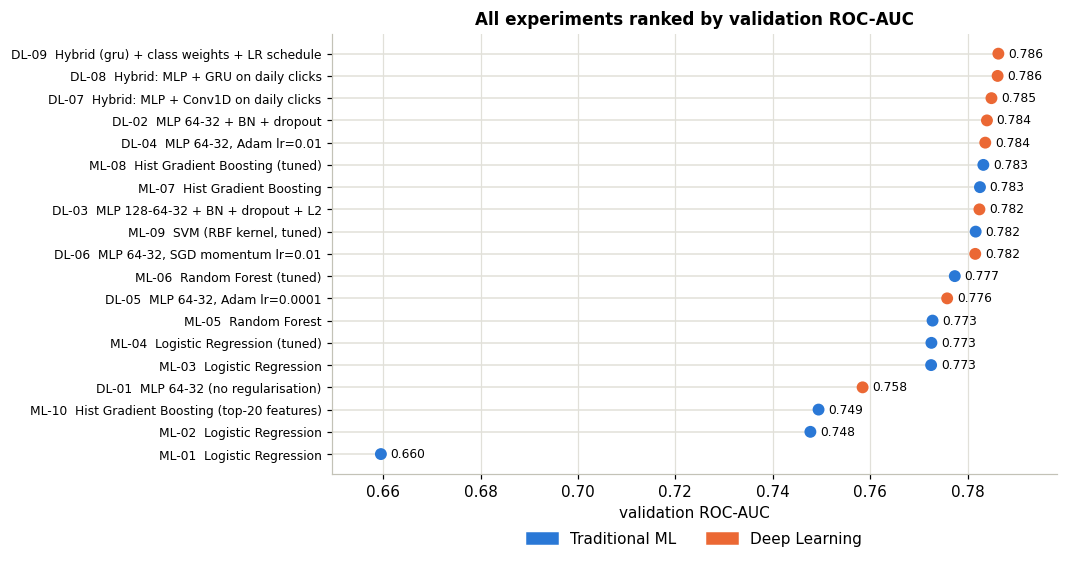

In [39]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
r = results.sort_values("val_auc")
colors = [BLUE if a == "Traditional ML" else ORANGE for a in r["approach"]]
labels = r["exp_id"] + "  " + r["model"]
ax.hlines(labels, r["val_auc"].min() - 0.01, r["val_auc"], color=GRID, lw=1)
ax.scatter(r["val_auc"], labels, color=colors, s=46, zorder=3)
for i, v in enumerate(r["val_auc"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(r["val_auc"].min() - 0.01, r["val_auc"].max() + 0.012)
ax.set_xlabel("validation ROC-AUC")
ax.set_title("All experiments ranked by validation ROC-AUC")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["Traditional ML", "Deep Learning"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
save_fig("fig05_experiment_ranking")

## 12. Evaluation

### 12.1 Choosing the two final models

The final traditional model and the final deep model are simply the ones with the highest validation ROC-AUC in their family.

In [40]:
best_ml_id = results[results["approach"] == "Traditional ML"].sort_values("val_auc").iloc[-1]["exp_id"]
best_dl_id = results[results["approach"] == "Deep Learning"].sort_values("val_auc").iloc[-1]["exp_id"]
by_id = {r["exp_id"]: r for r in RESULTS}
print("Best traditional model:", best_ml_id, "-", by_id[best_ml_id]["model"])
print("Best deep model:       ", best_dl_id, "-", by_id[best_dl_id]["model"])
results[results["exp_id"].isin([best_ml_id, best_dl_id])][
    ["exp_id", "model", "train_auc", "val_auc", "test_auc", "test_pr_auc", "test_acc", "test_precision", "test_recall", "test_f1"]].round(4)

Best traditional model: ML-08 - Hist Gradient Boosting (tuned)
Best deep model:        DL-09 - Hybrid (gru) + class weights + LR schedule


,exp_id,model,train_auc,val_auc,test_auc,test_pr_auc,test_acc,test_precision,test_recall,test_f1
8,DL-09,Hybrid (gru) + class weights + LR schedule,0.8160,0.7863,0.7904,0.7723,0.7212,0.6954,0.6588,0.6766
16,ML-08,Hist Gradient Boosting (tuned),0.8423,0.7832,0.7924,0.7720,0.7244,0.7171,0.6232,0.6669


**What I see:** on validation, DL-09 is ahead by 0.003. On the test set the order flips: ML-08 has the higher test AUC (0.7924 vs 0.7904), while DL-09 has slightly higher recall and F1 at 0.5. Both models generalise well. Their test AUC is a little **higher** than their validation AUC, so I did not overfit to the validation set while choosing them.

Because the ranking flips between validation and test, I test whether the difference is real in section 12.5 instead of declaring a winner.

### 12.2 Learning curves of the neural networks

Each panel shows training loss and validation loss per epoch for one deep learning experiment. The dotted line marks the epoch whose weights were kept.

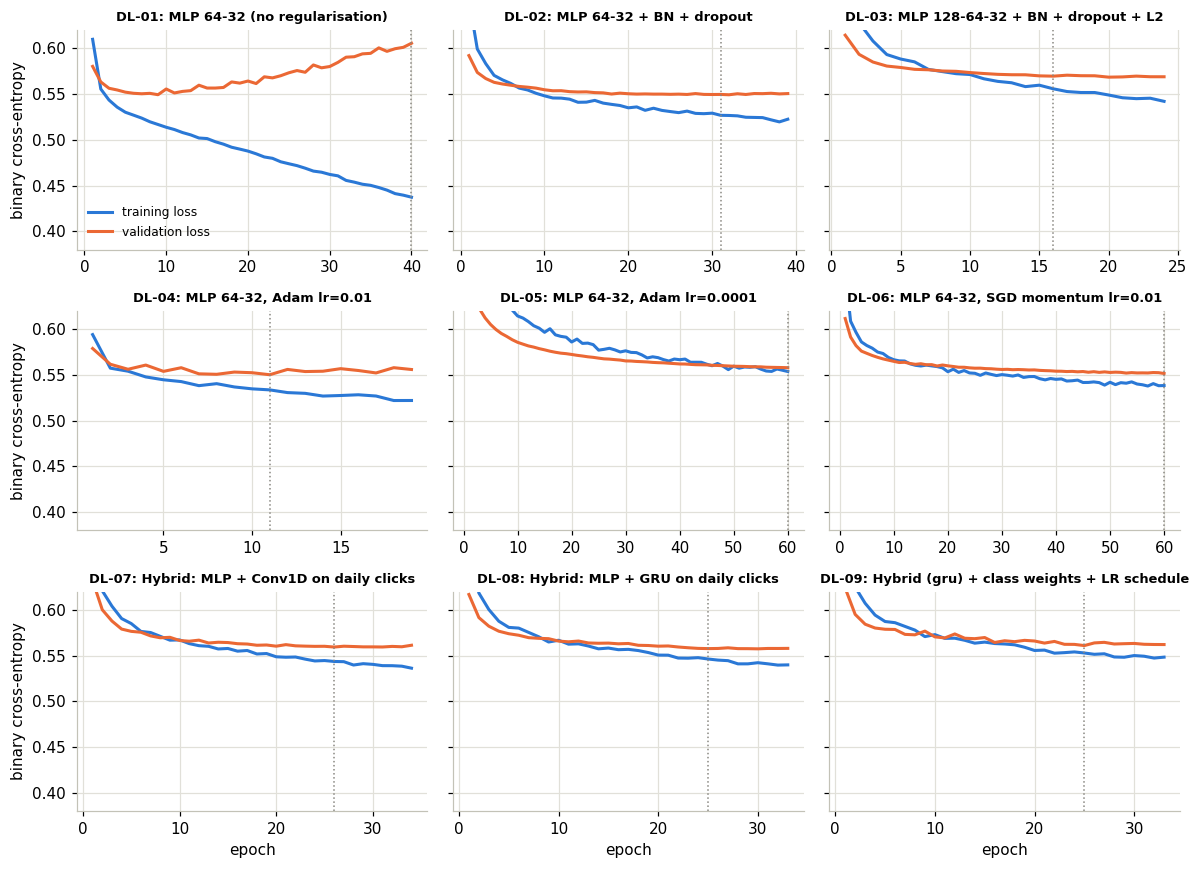

In [41]:
dl_ids = sorted(HISTORIES)
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharey=True)
for ax, exp_id in zip(axes.ravel(), dl_ids):
    h = HISTORIES[exp_id]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], color=BLUE, lw=2, label="training loss")
    ax.plot(ep, h["val_loss"], color=ORANGE, lw=2, label="validation loss")
    ax.axvline(by_id[exp_id]["best_epoch"], color=GREY, lw=1, ls=":")
    ax.set_title(f"{exp_id}: {by_id[exp_id]['model']}", fontsize=8.5)
    ax.set_ylim(0.38, 0.62)
for ax in axes[-1]:
    ax.set_xlabel("epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("binary cross-entropy")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
save_fig("fig06_dl_learning_curves")

In [42]:
curve_table = pd.DataFrame({exp_id: {"epochs run": len(h["loss"]),
                                     "kept epoch": by_id[exp_id]["best_epoch"],
                                     "train loss (kept)": h["loss"][by_id[exp_id]["best_epoch"] - 1],
                                     "val loss (kept)": h["val_loss"][by_id[exp_id]["best_epoch"] - 1],
                                     "lowest val loss": min(h["val_loss"]),
                                     "epoch of lowest val loss": int(np.argmin(h["val_loss"])) + 1,
                                     "final train loss": h["loss"][-1],
                                     "final val loss": h["val_loss"][-1],
                                     "val loss std (last 10 epochs)": float(np.std(h["val_loss"][-10:]))}
                            for exp_id, h in HISTORIES.items()}).T.round(4)
curve_table

,epochs run,kept epoch,train loss (kept),val loss (kept),lowest val loss,epoch of lowest val loss,final train loss,final val loss,val loss std (last 10 epochs)
DL-01,40.0,40.0,0.4373,0.6057,0.5494,9.0,0.4373,0.6057,0.0059
DL-02,39.0,31.0,0.5269,0.5497,0.5493,32.0,0.5226,0.5507,0.0005
DL-03,24.0,16.0,0.5559,0.5697,0.5686,20.0,0.5422,0.5690,0.0007
DL-04,19.0,11.0,0.5337,0.5503,0.5503,11.0,0.5221,0.5560,0.0023
DL-05,60.0,60.0,0.5538,0.5580,0.5580,60.0,0.5538,0.5580,0.0005
DL-06,60.0,60.0,0.5384,0.5516,0.5516,60.0,0.5384,0.5516,0.0004
DL-07,34.0,26.0,0.5438,0.5595,0.5595,26.0,0.5364,0.5615,0.0006
DL-08,33.0,25.0,0.5464,0.5578,0.5576,30.0,0.5400,0.5581,0.0003
DL-09,33.0,25.0,0.5530,0.5611,0.5611,25.0,0.5485,0.5623,0.0010


**What I see:**

* **DL-01** is the only clear case of **overfitting**. The curves cross at about epoch 9, then training loss keeps falling while validation loss rises. Because there was no early stopping, the final model is the overfitted epoch-40 one.
* **DL-02, DL-07, DL-08 and DL-09** show a healthy pattern. Validation loss flattens out while training loss keeps decreasing slowly, and early stopping keeps an epoch near where validation stopped improving. The small final gap (for example 0.527 vs 0.550 for DL-02) is the variance that dropout and batch norm could not remove.
* **DL-05 and DL-06** still have a downward slope at epoch 60, and their training and validation curves sit almost on top of each other. That is the signature of **underfitting**: they had not finished learning when they ran out of epochs.
* **DL-04** has the most uneven validation curve. That is what a learning rate that is too high looks like.

In the regularised models validation loss levels off around 0.55 to 0.56 whatever I change. That points to a limit in the data rather than in the networks.

### 12.3 Learning curve of the best traditional model

For the traditional model there are no epochs, so the learning curve shows what happens as the model is given more training rows. The gap between the two lines is the variance. The height they level off at shows the bias.

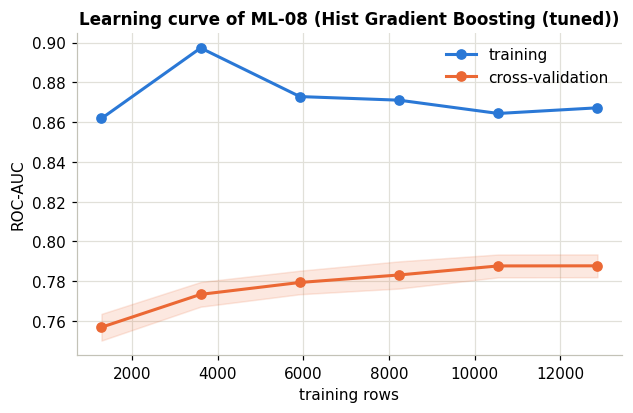

,training rows,train AUC,CV AUC,gap
0,1286,0.8618,0.7569,0.1050
1,3601,0.8973,0.7734,0.1239
2,5917,0.8729,0.7794,0.0935
3,8232,0.8711,0.7832,0.0879
4,10548,0.8644,0.7877,0.0767
5,12864,0.8672,0.7878,0.0795


In [43]:
cols = FEATURE_SETS[by_id[best_ml_id]["feature_set"]]
sizes, train_sc, cv_sc = learning_curve(clone(MODELS[best_ml_id]), X_train[cols], y_train, groups=g_train, cv=CV,
                                        scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1,
                                        shuffle=True, random_state=SEED)  # rows are sorted by module, so shuffle first
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(sizes, train_sc.mean(axis=1), "o-", color=BLUE, lw=2, label="training")
ax.plot(sizes, cv_sc.mean(axis=1), "o-", color=ORANGE, lw=2, label="cross-validation")
ax.fill_between(sizes, cv_sc.mean(axis=1) - cv_sc.std(axis=1), cv_sc.mean(axis=1) + cv_sc.std(axis=1), color=ORANGE, alpha=0.15)
ax.set_xlabel("training rows")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Learning curve of {best_ml_id} ({by_id[best_ml_id]['model']})")
ax.legend()
save_fig("fig07_ml_learning_curve")
pd.DataFrame({"training rows": sizes, "train AUC": train_sc.mean(axis=1), "CV AUC": cv_sc.mean(axis=1),
              "gap": train_sc.mean(axis=1) - cv_sc.mean(axis=1)}).round(4)

**What I see:** with only 1,286 training rows the model already reaches a CV AUC of **0.757**, and by about 10,500 rows it levels off at **0.788**. The last two points are almost identical (0.7877 and 0.7878). The gap between training and cross-validation stays around **0.08** from 8,000 rows onwards.

In bias-variance terms, the variance part is small and stable, and adding more students of the same kind would barely help. The remaining error is mostly **bias**, or more exactly irreducible noise for these features. What a student does in their first four weeks only tells us so much about how they will finish a 9-month course. To do better the model needs *different information* (for example later weeks, or data the dataset does not have), not more rows of the same information.

*(Note: training subsets are shuffled before sampling because the rows are sorted by course module. Without shuffling, the small subsets contained only one or two modules, and the curve wrongly suggested that more data would help a lot.)*

### 12.4 ROC and precision-recall curves on the test set

One curve per model family, using the best experiment of each family on validation.

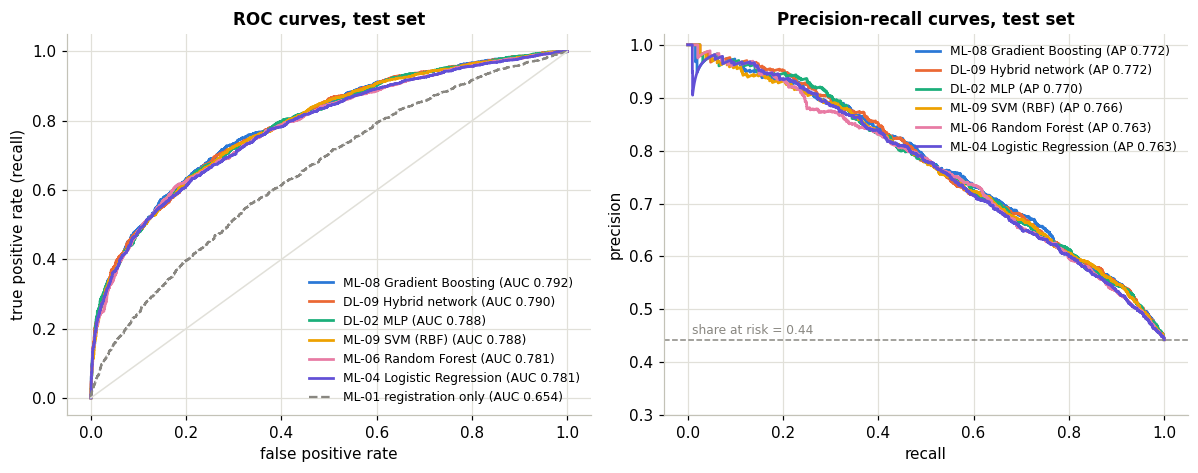

,exp_id,family,val_auc,test_auc,test_pr_auc,test_f1,fit_seconds
16,ML-08,Gradient Boosting,0.7832,0.7924,0.7720,0.6669,7.7330
8,DL-09,Hybrid network,0.7863,0.7904,0.7723,0.6766,20.7571
1,DL-02,MLP,0.7840,0.7881,0.7697,0.6571,3.8358
17,ML-09,SVM (RBF),0.7817,0.7875,0.7665,0.6313,28.8846
14,ML-06,Random Forest,0.7774,0.7813,0.7632,0.6543,31.8023
12,ML-04,Logistic Regression,0.7726,0.7806,0.7634,0.6492,7.2966


In [44]:
def family(row):
    name = row["model"]
    for key, fam in (("Logistic", "Logistic Regression"), ("Random Forest", "Random Forest"),
                     ("Gradient Boosting", "Gradient Boosting"), ("SVM", "SVM (RBF)"),
                     ("Hybrid", "Hybrid network"), ("MLP", "MLP")):
        if key in name:
            return fam
    return name


results["family"] = results.apply(family, axis=1)
champions = results.loc[results[results["feature_set"] != "registration"].groupby("family")["val_auc"].idxmax()] \
    .sort_values("test_auc", ascending=False)
palette = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for color, (_, row) in zip(palette, champions.iterrows()):
    s = SCORES[row["exp_id"]]["test"]
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    label = f"{row['exp_id']} {row['family']}"
    axes[0].plot(fpr, tpr, color=color, lw=1.8, label=f"{label} (AUC {row['test_auc']:.3f})")
    axes[1].plot(rec, prec, color=color, lw=1.8, label=f"{label} (AP {row['test_pr_auc']:.3f})")
base = by_id["ML-01"]
fpr, tpr, _ = roc_curve(y_test, SCORES["ML-01"]["test"])
axes[0].plot(fpr, tpr, color=GREY, lw=1.5, ls="--", label=f"ML-01 registration only (AUC {base['test_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curves, test set")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), color=GREY, lw=1, ls="--")
axes[1].text(0.01, y_test.mean() + 0.01, f"share at risk = {y_test.mean():.2f}", color=GREY, fontsize=8)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_ylim(0.3, 1.02)
axes[1].set_title("Precision-recall curves, test set")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
save_fig("fig08_roc_pr")
champions[["exp_id", "family", "val_auc", "test_auc", "test_pr_auc", "test_f1", "fit_seconds"]].round(4)

**What I see:** the six best models from each family have ROC curves that lie almost on top of each other (test AUC 0.781 to 0.792). All of them are far above the registration-only baseline (dashed, 0.654) and the diagonal (chance).

The precision-recall plot tells the same story in more practical terms. The dashed line is the 0.44 share of at-risk students, which is what a random guess would get. All models stay well above it. Around 80% recall they keep about 60% precision. Below 20% recall they reach over 90% precision, so the students the models are *most* sure about are nearly always truly at risk. Average precision ranges from 0.763 to 0.772, so again the families are nearly tied.

### 12.5 Is the difference between the two best models real?

The final traditional and deep models score very close to each other. To check if the gap is bigger than chance, I resample the test set with replacement 1,000 times. Each time I compute both models' ROC-AUC on the same resample. This gives a 95% interval for each AUC and for the difference between them.

In [45]:
def paired_bootstrap_auc(y_true, scores_a, scores_b, n_boot=1000, seed=SEED):
    """Bootstrap the test set and compare two models' AUC on the same resamples."""
    rng = np.random.default_rng(seed)
    a, b = [], []
    for _ in range(n_boot):
        ix = rng.integers(0, len(y_true), len(y_true))
        a.append(roc_auc_score(y_true[ix], scores_a[ix]))
        b.append(roc_auc_score(y_true[ix], scores_b[ix]))
    a, b = np.array(a), np.array(b)
    ci = lambda v: f"[{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]"
    return pd.DataFrame({"mean": [a.mean(), b.mean(), (a - b).mean()],
                         "95% interval": [ci(a), ci(b), ci(a - b)]},
                        index=["AUC A", "AUC B", "A minus B"]).round(4), float((a > b).mean())


boot, share = paired_bootstrap_auc(y_test, SCORES[best_ml_id]["test"], SCORES[best_dl_id]["test"])
boot.index = [f"{best_ml_id} AUC", f"{best_dl_id} AUC", f"{best_ml_id} minus {best_dl_id}"]
print(f"{best_ml_id} beats {best_dl_id} in {share:.0%} of the 1,000 resamples")
boot

ML-08 beats DL-09 in 78% of the 1,000 resamples


,mean,95% interval
ML-08 AUC,0.7924,"[0.7793, 0.8057]"
DL-09 AUC,0.7903,"[0.7757, 0.8041]"
ML-08 minus DL-09,0.0021,"[-0.0030, 0.0073]"


**What I see:** across 1,000 bootstrap resamples of the test set, ML-08's AUC is 0.7924 (95% interval 0.779 to 0.806) and DL-09's is 0.7903 (0.776 to 0.804). The intervals overlap almost completely. The interval for the difference, **-0.003 to +0.007**, includes zero. ML-08 wins in 78% of resamples, which is a lean, not a result.

**Conclusion:** on this data the best traditional model and the best deep model are **statistically tied**. Given a tie, I would recommend gradient boosting for real use. It trains in seconds, needs no GPU, takes raw tabular input and is easier to explain to tutors. The deep model is a good piece of evidence that sequence models do not add much here, but not a reason to deploy something more complex.

### 12.6 Choosing a decision threshold

A threshold of 0.5 treats both kinds of error as equally bad. For this problem they are not. Missing an at-risk student means nobody contacts them. Wrongly flagging a student costs a tutor one unnecessary message. So I pick the threshold on the **validation** set: the highest threshold that still catches at least 80% of at-risk students. I then apply that fixed threshold to the test set.

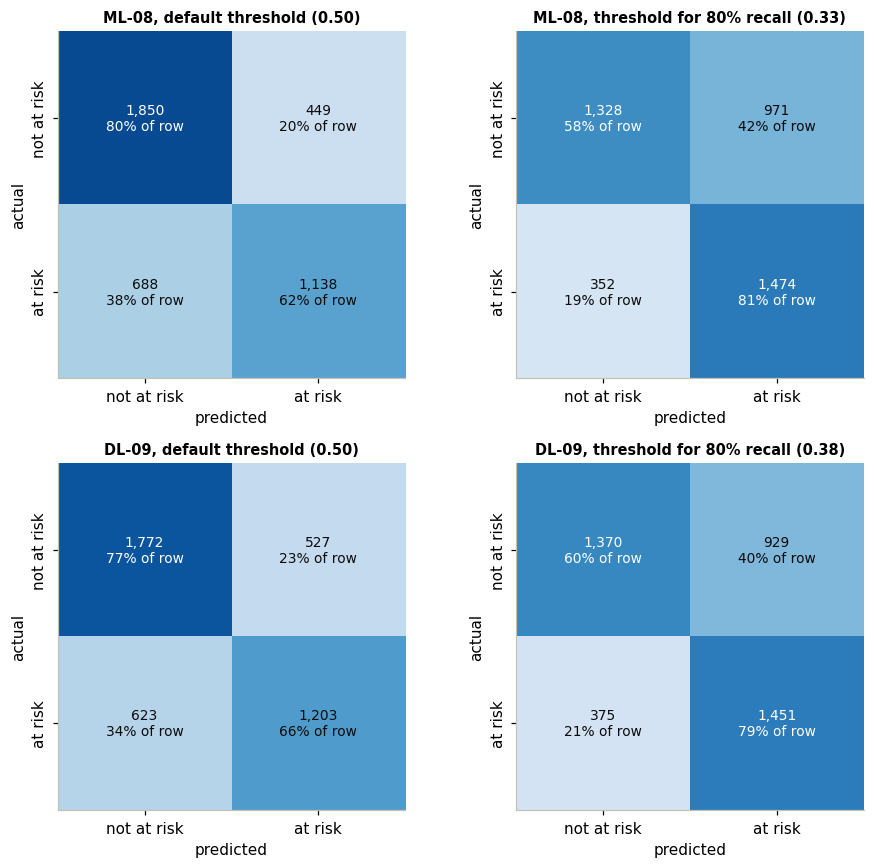

,exp_id,threshold,value,acc,precision,recall,f1
0,ML-08,default threshold,0.500,0.7244,0.7171,0.6232,0.6669
1,ML-08,threshold for 80% recall,0.331,0.6793,0.6029,0.8072,0.6902
2,DL-09,default threshold,0.500,0.7212,0.6954,0.6588,0.6766
3,DL-09,threshold for 80% recall,0.378,0.6839,0.6097,0.7946,0.6900


In [46]:
def pick_threshold(y_true, scores, min_recall=0.80):
    """Highest threshold whose recall is still at least min_recall."""
    prec, rec, thr = precision_recall_curve(y_true, scores)
    ok = np.where(rec[:-1] >= min_recall)[0]
    return float(thr[ok[-1]])


def confusion_panel(ax, y_true, scores, threshold, title):
    cm = confusion_matrix(y_true, (scores >= threshold).astype(int))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum() * 0.5)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}\n{v / cm[i].sum():.0%} of row", ha="center", va="center",
                color="white" if v > cm.sum() * 0.3 else "#0b0b0b", fontsize=9)
    ax.set_xticks([0, 1], ["not at risk", "at risk"])
    ax.set_yticks([0, 1], ["not at risk", "at risk"], rotation=90, va="center")
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(title, fontsize=9.5)
    ax.grid(False)
    return cm


FINAL = {}
fig, axes = plt.subplots(2, 2, figsize=(8.6, 8))
rows = []
for r_i, exp_id in enumerate([best_ml_id, best_dl_id]):
    sc = SCORES[exp_id]
    tuned = pick_threshold(y_val, sc["val"])
    FINAL[exp_id] = tuned
    for c_i, (thr, label) in enumerate([(sc["threshold"], "default threshold"), (tuned, "threshold for 80% recall")]):
        confusion_panel(axes[r_i, c_i], y_test, sc["test"], thr, f"{exp_id}, {label} ({thr:.2f})")
        rows.append({"exp_id": exp_id, "threshold": label, "value": round(thr, 3),
                     **{k: round(v, 4) for k, v in evaluate(y_test, sc["test"], thr).items() if k not in ("auc", "pr_auc")}})
plt.tight_layout()
save_fig("fig09_confusion_matrices")
pd.DataFrame(rows)

**What I see:**

* At the default 0.5 threshold, ML-08 misses **688 of 1,826** at-risk students (38%). DL-09 misses 623 (34%). For an early-warning tool that is too many.
* Lowering the threshold to the value chosen on validation (0.33 for ML-08, 0.38 for DL-09) brings recall on the **test** set to **80.7%** and **79.5%**. So the threshold picked on validation carried over to new students almost exactly.
* The cost is more false alarms. ML-08 now wrongly flags 971 of 2,299 students who were fine (42%), and precision drops from 0.717 to 0.603.

I think this trade is the right one. A false alarm costs a tutor one email or call, while a missed student may drop out. F1 actually goes **up** with the lower threshold (0.667 to 0.690 for ML-08). Still, the exact threshold is a decision for the people running the intervention, depending on how many students they can contact.

### 12.7 Which features does the best traditional model rely on?

Permutation importance shuffles one input column at a time on the validation set and measures how much ROC-AUC drops. A large drop means the model depends on that column.

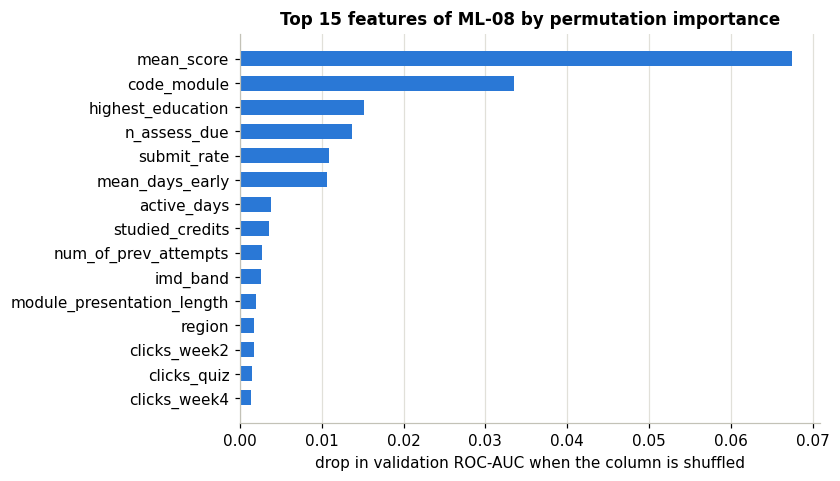

assessment      0.1026
registration    0.0635
VLE activity    0.0156


,importance
mean_score,0.0675
code_module,0.0335
highest_education,0.0152
n_assess_due,0.0137
submit_rate,0.0109
mean_days_early,0.0106
active_days,0.0038
studied_credits,0.0035
num_of_prev_attempts,0.0027
imd_band,0.0025


In [47]:
cols = FEATURE_SETS[by_id[best_ml_id]["feature_set"]]
perm = permutation_importance(MODELS[best_ml_id], X_val[cols], y_val, scoring="roc_auc", n_repeats=5,
                              random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.barh(top.index, top.values, color=BLUE, height=0.62)
ax.set_xlabel("drop in validation ROC-AUC when the column is shuffled")
ax.set_title(f"Top 15 features of {best_ml_id} by permutation importance")
ax.grid(axis="y", visible=False)
save_fig("fig10_feature_importance")
group_of = lambda c: "registration" if c in FEATURE_SETS["registration"] else ("assessment" if c in ASSESS_LOG + ASSESS_NUM else "VLE activity")
print(imp.groupby(group_of).sum().sort_values(ascending=False).round(4).rename("summed importance").to_string())
imp.head(10).round(4).rename("importance").to_frame()

**What I see:** the single most important feature is `mean_score`, the average mark on early coursework (a drop of 0.068 AUC when it is shuffled). It is followed by `code_module` (0.034) and prior education (0.015). Summed by group, assessment features matter most (0.103), then registration (0.064), then VLE activity (only 0.016).

That last number looks like it contradicts section 9.1, where VLE features added +0.088 AUC. It does not. I have about 25 VLE columns and they are highly correlated (total clicks, active days, weekly clicks...). When one is shuffled, the model can still get the same information from the others, so each one looks unimportant on its own. Permutation importance **underestimates groups of correlated features**, and the ablation in 9.1 is the more reliable measure of what VLE data adds.

## 13. Error analysis

The overall numbers hide **who** the model gets wrong. Here I take the best overall model at its tuned threshold and look at its test-set errors from four angles.

In [48]:
overall_id = best_ml_id if by_id[best_ml_id]["val_auc"] >= by_id[best_dl_id]["val_auc"] else best_dl_id
thr = FINAL[overall_id]
test_df = data.iloc[test_idx].copy()
test_df["score"] = SCORES[overall_id]["test"]
test_df["pred"] = (test_df["score"] >= thr).astype(int)
test_df["error"] = np.select([(test_df["pred"] == 1) & (test_df["at_risk"] == 1), (test_df["pred"] == 0) & (test_df["at_risk"] == 0),
                              (test_df["pred"] == 1) & (test_df["at_risk"] == 0)], ["TP", "TN", "FP"], default="FN")
print(f"Model analysed: {overall_id} at threshold {thr:.3f}")
print(test_df["error"].value_counts().to_string())

Model analysed: DL-09 at threshold 0.378
error
TP    1451
TN    1370
FP     929
FN     375


### 13.1 Errors by true final result

The binary target merges four outcomes into two. This table splits them apart again to see which of the original outcomes are hard.

In [49]:
by_result = test_df.groupby("final_result").agg(students=("pred", "size"), flagged_at_risk=("pred", "mean"),
                                                mean_score=("score", "mean")).reindex(order)
by_result["correct"] = [1 - by_result.loc[o, "flagged_at_risk"] if o in ("Distinction", "Pass") else by_result.loc[o, "flagged_at_risk"] for o in order]
by_result.round(3)

,students,flagged_at_risk,mean_score,correct
final_result,,,,
Distinction,434,0.228,0.276,0.772
Pass,1865,0.445,0.385,0.555
Fail,1054,0.808,0.619,0.808
Withdrawn,772,0.776,0.619,0.776


**What I see:** the model's errors are not spread evenly across the four original outcomes:

* It catches **80.8%** of students who will fail and **77.6%** of those who will withdraw.
* It wrongly flags only 22.8% of Distinction students but **44.5% of Pass students**.

So most false alarms come from students who end up passing. This makes sense. "Pass" covers everyone from a strong student to someone who scraped through, and in the first four weeks a student who passes narrowly can look just like one who fails.

### 13.2 What do the missed students look like?

False negatives are at-risk students the model did not flag. I compare their early behaviour with the at-risk students it did catch (true positives) and with students who really were fine (true negatives).

In [50]:
profile_cols = ["total_clicks", "active_days", "last_active_day", "clicks_week4", "n_submitted", "submit_rate", "mean_score", "studied_credits"]
profile = test_df.groupby("error")[profile_cols].median().reindex(["TP", "FN", "TN", "FP"])
profile.insert(0, "students", test_df["error"].value_counts().reindex(profile.index))
profile.round(2)

,students,total_clicks,active_days,last_active_day,clicks_week4,n_submitted,submit_rate,mean_score,studied_credits
error,,,,,,,,,
TP,1451,117.0,8.0,24.0,7.0,1.0,1.0,66.5,60.0
FN,375,350.0,16.0,26.0,44.0,1.0,1.0,82.0,60.0
TN,1370,407.0,19.0,26.0,55.0,1.0,1.0,85.0,60.0
FP,929,168.0,10.0,25.0,15.0,1.0,1.0,71.0,60.0


In [51]:
fn = test_df[test_df["error"] == "FN"]
print("False negatives by final result:")
print(fn["final_result"].value_counts().to_string())
late_leavers = fn[fn["final_result"] == "Withdrawn"]["date_unregistration"]
print(f"\nWithdrawn students who were missed: median withdrawal day = {late_leavers.median():.0f}")
caught = test_df[(test_df["error"] == "TP") & (test_df["final_result"] == "Withdrawn")]["date_unregistration"]
print(f"Withdrawn students who were caught: median withdrawal day = {caught.median():.0f}")

False negatives by final result:
final_result
Fail         202
Withdrawn    173

Withdrawn students who were missed: median withdrawal day = 125
Withdrawn students who were caught: median withdrawal day = 101


**What I see:** the missed at-risk students (FN) look almost exactly like students who were fine (TN). Their median clicks are 350 vs 407, active days 16 vs 19, week-4 clicks 44 vs 55, and early score 82 vs 85. The students the model catches (TP) look completely different: 117 clicks, 8 active days, a score of 66.5.

The withdrawal dates explain part of this. The withdrawn students the model missed left on day **125** (median), compared with day **101** for those it caught. These students were engaged and doing well in the first month, and something changed later. **No model that only sees the first 28 days can see that coming.** This is a limit of the problem setup, not of a particular algorithm, and it is the strongest argument for re-running the model at several points in the course.

### 13.3 Errors by course module

In [52]:
def slice_metrics(df, by):
    """Recall, precision and false-positive rate inside each group."""
    out = []
    for name, g in df.groupby(by, observed=True):
        tp, fn_, fp, tn = [(g["error"] == e).sum() for e in ("TP", "FN", "FP", "TN")]
        out.append({by: name, "students": len(g), "% at risk": 100 * g["at_risk"].mean(),
                    "recall": tp / max(tp + fn_, 1), "precision": tp / max(tp + fp, 1),
                    "false positive rate": fp / max(fp + tn, 1),
                    "AUC": roc_auc_score(g["at_risk"], g["score"]) if g["at_risk"].nunique() == 2 else np.nan})
    return pd.DataFrame(out).set_index(by).round(3)


slice_metrics(test_df, "code_module")

,students,% at risk,recall,precision,false positive rate,AUC
code_module,,,,,,
AAA,110,29.091,0.469,0.536,0.167,0.749
BBB,944,40.678,0.750,0.553,0.416,0.754
CCC,539,52.319,0.858,0.674,0.455,0.804
DDD,772,52.073,0.876,0.693,0.422,0.833
EEE,362,35.359,0.695,0.597,0.256,0.788
FFF,1017,43.854,0.803,0.606,0.408,0.800
GGG,381,39.895,0.704,0.478,0.511,0.656


**What I see:** performance varies a lot between courses. AUC is **0.833** in DDD and 0.804 in CCC but only **0.656** in GGG. In GGG precision is under 0.5 and more than half of the students who were fine are flagged (false positive rate 0.511). Module AAA has the lowest recall (0.469), but it only has 110 test students, so that number is not very reliable.

GGG is a hard case. My guess is that its early weeks look different (for example less VLE use or different assessment timing), so the patterns learned mostly from other modules do not transfer well. A per-module threshold, or a separate model for courses like GGG, would be worth testing.

### 13.4 Errors by deprivation band, gender and disability

A model that is used to decide who gets support should work about equally well for different groups of students. I group the ten deprivation bands into three for stable numbers.

In [53]:
imd_group = {b: "most deprived (0-30%)" for b in imd_order[:3]}
imd_group.update({b: "middle (30-70%)" for b in imd_order[3:7]})
imd_group.update({b: "least deprived (70-100%)" for b in imd_order[7:]})
test_df["imd_group"] = test_df["imd_band"].map(imd_group).fillna("not recorded")
fair = pd.concat({"deprivation": slice_metrics(test_df, "imd_group"),
                  "gender": slice_metrics(test_df, "gender"),
                  "disability": slice_metrics(test_df, "disability")})
fair

students  % at risk  recall  precision  \
deprivation least deprived (70-100%)      1066     38.368   0.709      0.575   
            middle (30-70%)               1579     42.875   0.781      0.596   
            most deprived (0-30%)         1318     52.807   0.874      0.649   
            not recorded                   162     27.160   0.545      0.471   
gender      F                             1893     43.476   0.765      0.589   
            M                             2232     44.937   0.819      0.627   
disability  N                             3739     43.193   0.777      0.605   
            Y                              386     54.663   0.929      0.641   

                                      false positive rate    AUC  
deprivation least deprived (70-100%)                0.326  0.767  
            middle (30-70%)                         0.398  0.789  
            most deprived (0-30%)                   0.529  0.799  
            not recorded                            0.229  0.716  
gender      F                                       0.411  0.766  
            M                                       0.398  0.810  
disability  N                                       0.386  0.790  
            Y                                       0.629  0.777

**What I see:**

* **Deprivation:** ranking quality is similar across groups (AUC 0.767 to 0.799), but with one shared threshold the model flags far more students from deprived areas. The false positive rate is **0.529** in the most deprived group and **0.326** in the least deprived. Part of this follows from the base rates (52.8% vs 38.4% at risk), but it means a support programme driven by this model would contact many more students from poorer areas who would have been fine. If the contact is supportive, that may be acceptable. If being flagged had any negative effect, it would not be.
* **Gender:** the model ranks men's outcomes better than women's (AUC **0.810 vs 0.766**) and catches more at-risk men (recall 0.819 vs 0.765). This is the gap I find most worrying, because I cannot explain it from base rates (43.5% vs 44.9%).
* **Disability:** students with a declared disability have a higher at-risk rate (54.7%), very high recall (0.929) and a high false positive rate (0.629).
* **Missing IMD band** (162 students) has the weakest AUC (0.716), likely because the group is small.

None of these features were removed. Because deprivation and module are genuinely linked to outcomes, removing them would not remove the bias, it would only hide it. The better fix is to audit these numbers regularly and consider group-specific thresholds.

## 14. Saving the best models

The best traditional pipeline is saved with `joblib` (preprocessing and model together). The best deep model is saved in the native `.keras` format, with the fitted preprocessor next to it because the network needs the same transformed inputs. These files go to the Google Drive folder, not to GitHub.

The last lines reload both files and check that they reproduce the same test ROC-AUC.

In [54]:
ml_path = MODEL_DIR / f"best_traditional_{best_ml_id}.joblib"
dl_path = MODEL_DIR / f"best_deep_{best_dl_id}.keras"
prep_path = MODEL_DIR / "deep_model_preprocessor.joblib"
joblib.dump(MODELS[best_ml_id], ml_path)
MODELS[best_dl_id].save(dl_path)
joblib.dump(dl_prep, prep_path)
json.dump({"cutoff_day": CUTOFF_DAY, "seq_start": SEQ_START, "features": FEATURE_SETS["all"],
           "thresholds": FINAL, "best_traditional": best_ml_id, "best_deep": best_dl_id},
          open(MODEL_DIR / "model_card.json", "w"), indent=2)

ml_loaded = joblib.load(ml_path)
dl_loaded = keras.models.load_model(dl_path)
uses_seq = len(dl_loaded.inputs) == 2
dl_scores = dl_loaded.predict(make_dataset("test", 1024, use_seq=uses_seq), verbose=0).ravel()
print(f"{ml_path.name}: test AUC after reload = {roc_auc_score(y_test, model_scores(ml_loaded, X_test[FEATURE_SETS[by_id[best_ml_id]['feature_set']]])):.4f}")
print(f"{dl_path.name}: test AUC after reload = {roc_auc_score(y_test, dl_scores):.4f}")
for p in (ml_path, dl_path, prep_path):
    print(f"  {p}  {p.stat().st_size / 1024:.0f} KB")

best_traditional_ML-08.joblib: test AUC after reload = 0.7924
best_deep_DL-09.keras: test AUC after reload = 0.7904
  models/best_traditional_ML-08.joblib  453 KB
  models/best_deep_DL-09.keras  228 KB
  models/deep_model_preprocessor.joblib  10 KB


## 15. Conclusions

1. **The problem is learnable, but only up to a point.** Using only the first 28 days, the best models reach a test ROC-AUC of about **0.79**. At a threshold chosen for 80% recall they catch about 4 in 5 at-risk students, with roughly 60% precision.
2. **Feature engineering mattered more than the choice of algorithm.** Going from registration data to registration + VLE + assessment features added **0.113** AUC to the same Logistic Regression. Switching from the best linear model to the best deep model added about **0.014**.
3. **Traditional ML and deep learning are statistically tied.** The best gradient boosting model (ML-08) and the best two-input GRU network (DL-09) are 0.002 apart on test AUC, and the bootstrap interval of the difference includes zero. For deployment I would choose gradient boosting, because it is faster, simpler and easier to explain.
4. **Regularisation was essential for the networks.** Without it (DL-01) the MLP overfitted after 9 epochs and did worse than Logistic Regression. With batch norm, dropout and early stopping it matched the best tree model.
5. **The remaining errors are mostly about time, not models.** Missed students look engaged and successful in month one and withdraw much later (median day 125). The learning curve has flattened, so more of the same data will not fix this.
6. **The model is not equally good for everyone.** It ranks men's outcomes better than women's and flags students from deprived areas much more often. Any real use would need regular fairness checks.

**Next steps I would try:** re-scoring students every few weeks instead of once on day 28; per-module thresholds or models (especially for GGG); a temporal test where I train on 2013 presentations and test on 2014 ones; and calibrating the probabilities so that a score of 0.7 really means a 70% chance.